# I. Mục tiêu khám phá dữ liệu

Notebook này dùng để **khám phá dữ liệu (EDA)** cho bài toán dự báo PM2.5 tại Hoàn Kiếm.

EDA trong notebook không chỉ để vẽ biểu đồ mà phải trả lời các câu hỏi phục vụ cho các bước sau:

1. Dữ liệu có đủ liên tục và đáng tin cậy để làm chuỗi thời gian không?
2. PM2.5 có phân phối và mức biến động như thế nào?
3. Có quy luật theo giờ, ngày, tháng, mùa hay không?
4. PM2.5 phụ thuộc vào lịch sử của chính nó trong bao lâu?
5. Forecast horizon càng xa thì bài toán khó lên như thế nào?
6. Các chất ô nhiễm khác có chứa thông tin cho PM2.5 tương lai không?
7. Yếu tố khí tượng có quan hệ tuyến tính hay phi tuyến với PM2.5?
8. Quan hệ khí tượng - PM2.5 có thay đổi theo mùa không?
9. Hướng gió, mưa và tổ hợp các điều kiện khí tượng có liên hệ gì với PM2.5?
10. Các đợt PM2.5 cao có phải chỉ là spike lẻ hay kéo dài thành episode?
11. Phân phối dữ liệu có thay đổi giữa các năm không?

**Notebook này chưa tạo feature, chưa scale dữ liệu, chưa chia Train/Validation/Test và chưa train model.**

**Lưu ý phạm vi.** EDA chạy trên toàn bộ chuỗi 2022–2026, tức là có cả giai đoạn sau này dùng làm Test.
Một số quyết định chọn biến (bỏ Dew Point, giữ Soil Moisture) vì vậy đã "nhìn thấy" Test.
Mục 10.4b kiểm tra lại kết luận quan trọng nhất chỉ trên 70% đầu chuỗi để xem có thay đổi không,
và điều này được ghi thành hạn chế ở mục XV.

**Cột AQI bị loại ngay từ đầu.** AQI là chỉ số tính lại từ nồng độ các chất (lấy chất xấu nhất),
không đơn điệu theo PM2.5 và không dùng làm đầu vào ở các bước sau, nên giữ lại chỉ gây nhiễu khi đọc bảng.


# II. Import Data

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')


In [ ]:
# Notebook nằm trong notebooks/, dữ liệu ở data/processed/
df = pd.read_csv('../data/processed/cleaned_data.csv')
print(f'Kích thước dữ liệu gốc: {df.shape[0]} dòng, {df.shape[1]} cột')

# Bỏ AQI: chỉ số tổng hợp, không dùng làm đầu vào ở các bước sau
df = df.drop(columns=[c for c in ['AQI'] if c in df.columns])
df_raw = df.copy()

print(f'Sau khi bỏ AQI: {df.shape[0]} dòng, {df.shape[1]} cột')
display(df.head())

In [ ]:
df['Local Time'] = pd.to_datetime(df['Local Time'], errors='coerce')

df = df.sort_values('Local Time').reset_index(drop=True)

print('Bắt đầu:', df['Local Time'].min())
print('Kết thúc:', df['Local Time'].max())
print('Số dòng:', len(df))
print('\nCác cột:')
print(df.columns.tolist())


# III. Chất lượng và độ liên tục của dữ liệu

## 3.1 Missing value và timestamp trùng

In [ ]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    'Số giá trị thiếu': missing,
    'Tỷ lệ (%)': missing / len(df) * 100
})

if len(missing_table) == 0:
    print('Không cột nào có giá trị thiếu')
else:
    display(missing_table.round(4))

duplicate_mask = df.duplicated(subset='Local Time', keep=False)

print('Số dòng có timestamp trùng:', duplicate_mask.sum())
print('Số timestamp bị trùng:', df.loc[duplicate_mask, 'Local Time'].nunique())


**Nhận xét.** Sau khi bỏ cột AQI (cột duy nhất có giá trị thiếu, 18 giờ), dữ liệu không còn giá trị thiếu
và không có timestamp trùng.
Tuy vậy vẫn cần kiểm tra hai thứ nữa trước khi coi là dùng được:
khoảng thời gian có thực sự liên tục từng giờ không (phần tiếp theo),
và các giá trị được ghi có hợp lý về mặt vật lý không (mục 4.1 và 4.2).

## 3.2 Chuỗi có liên tục theo giờ không

Không thiếu giá trị chưa chắc đã liên tục: vẫn có thể bị mất hẳn một khoảng thời gian.
Đếm số giờ bị nhảy so với lưới giờ lý thuyết sẽ thấy ngay.

In [5]:
ts_idx = pd.DatetimeIndex(df['Local Time'])

full_index = pd.date_range(ts_idx.min(), ts_idx.max(), freq='h')
missing_hours = full_index.difference(ts_idx)

gap = ts_idx.to_series().diff().dt.total_seconds() / 3600

print('Số giờ theo lưới lý thuyết:', len(full_index))
print('Số giờ có dữ liệu          :', len(df))
print('Số giờ bị thiếu            :', len(missing_hours))
print('Số lần bị nhảy quá 1 giờ   :', int((gap > 1).sum()))

if len(missing_hours) > 0:
    display(pd.Series(missing_hours).dt.date.value_counts().head(10).to_frame('Số giờ thiếu'))

Số giờ theo lưới lý thuyết: 40608
Số giờ có dữ liệu          : 40608
Số giờ bị thiếu            : 0
Số lần bị nhảy quá 1 giờ   : 0


**Nhận xét.** Nếu số giờ thiếu bằng 0 và không có lần nhảy nào quá 1 giờ thì chuỗi liên tục hoàn toàn.
Khi đó không cần nội suy thời gian, mọi vấn đề còn lại (nếu có) đều là outlier về biên độ.

# IV. Biến mục tiêu PM2.5

## 4.1 Phân phối và các mức cực trị

In [6]:
ts = df.set_index('Local Time').sort_index()
pm25 = ts['PM25'].dropna()

pm25_stats = pd.Series({
    'Count': pm25.count(),
    'Mean': pm25.mean(),
    'Median': pm25.median(),
    'Std': pm25.std(),
    'IQR': pm25.quantile(0.75) - pm25.quantile(0.25),
    'P75': pm25.quantile(0.75),
    'P95': pm25.quantile(0.95),
    'Max': pm25.max(),
    'Skewness': pm25.skew(),
    'CV': pm25.std() / pm25.mean()
})

display(pm25_stats.to_frame('PM2.5'))


,PM2.5
Count,40608.000
Mean,43.334
Median,34.400
Std,32.605
IQR,29.500
P75,52.500
P95,110.700
Max,400.000
Skewness,2.309
CV,0.752


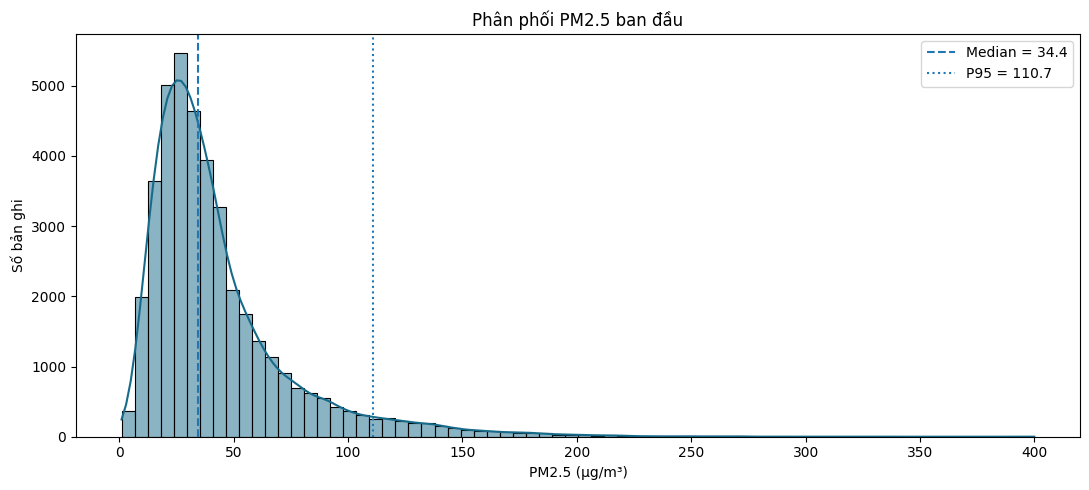

In [7]:
plt.figure(figsize=(11, 5))
sns.histplot(pm25, bins=70, kde=True, color='#176B8A')
plt.axvline(pm25.median(), linestyle='--', label=f'Median = {pm25.median():.1f}')
plt.axvline(pm25.quantile(0.95), linestyle=':', label=f'P95 = {pm25.quantile(0.95):.1f}')
plt.title('Phân phối PM2.5 ban đầu')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Số bản ghi')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
peak_cols = [col for col in ['PM25', 'PM10', 'CO', 'NO2', 'O3', 'SO2'] if col in ts.columns]
peak_table = ts[peak_cols].sort_values('PM25', ascending=False).head(15)

print('15 mốc PM2.5 cao nhất:')
display(peak_table)

In [ ]:
# Rolling median và Z-score trên phần dư PM2.5
rolling_median = ts['PM25'].rolling(window=24, center=True, min_periods=6).median()
residual = ts['PM25'] - rolling_median

residual_std = residual.std()
if pd.notna(residual_std) and residual_std > 0:
    z_score = (residual - residual.mean()) / residual_std
else:
    z_score = pd.Series(np.nan, index=ts.index)

outlier_flag = (z_score.abs() > 3) & ts['PM25'].notna()

print('Số điểm nghi ngờ outlier (|z| > 3):', int(outlier_flag.sum()))

outlier_table = ts.loc[outlier_flag, ['PM25', 'PM10']].copy()
outlier_table['Rolling Median 24h'] = rolling_median.loc[outlier_flag]
outlier_table['Z-score'] = z_score.loc[outlier_flag]

print('15 điểm có |Z-score| cao nhất:')
display(outlier_table.reindex(z_score.loc[outlier_flag].abs().sort_values(ascending=False).index).head(15))

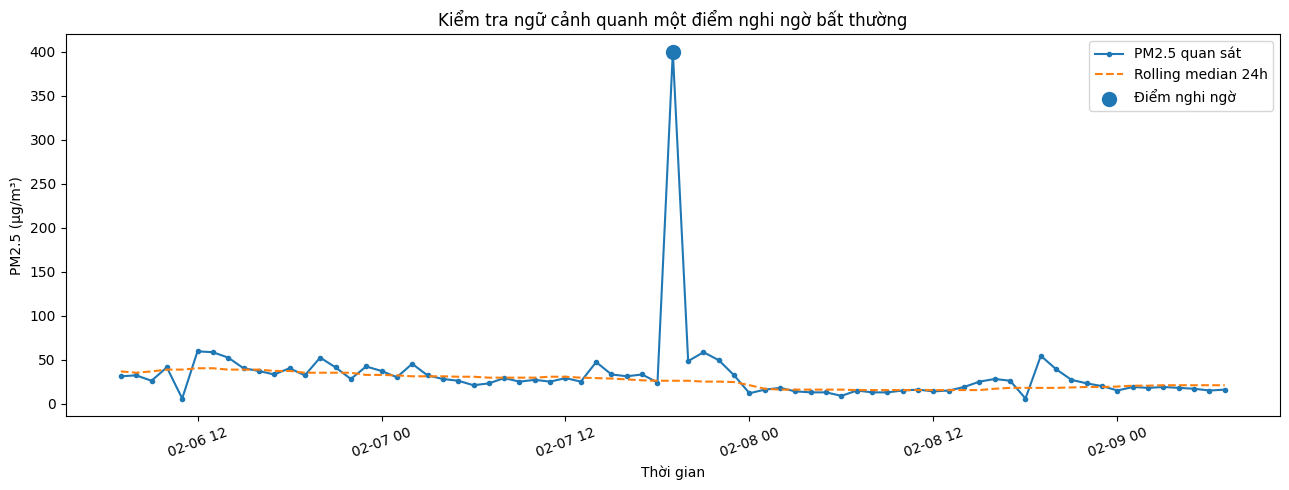

In [10]:
# Vẽ một đoạn thời gian xung quanh điểm nghi ngờ mạnh nhất
if outlier_flag.any():
    candidate_time = z_score.abs().idxmax()
    plot_start = candidate_time - pd.Timedelta(hours=36)
    plot_end = candidate_time + pd.Timedelta(hours=36)
    window_pm25 = ts.loc[plot_start:plot_end, 'PM25']
    window_median = rolling_median.loc[plot_start:plot_end]

    plt.figure(figsize=(13, 5))
    plt.plot(window_pm25.index, window_pm25, marker='.', label='PM2.5 quan sát')
    plt.plot(window_median.index, window_median, linestyle='--', label='Rolling median 24h')
    plt.scatter([candidate_time], [ts.loc[candidate_time, 'PM25']], s=100, label='Điểm nghi ngờ')
    plt.title('Kiểm tra ngữ cảnh quanh một điểm nghi ngờ bất thường')
    plt.xlabel('Thời gian')
    plt.ylabel('PM2.5 (µg/m³)')
    plt.xticks(rotation=20)
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Không phát hiện điểm vượt ngưỡng Z-score khảo sát.')

**Nhận xét.** PM2.5 lệch phải, median chỉ khoảng 34 nhưng đuôi kéo tới 400 µg/m³.
Có vài trăm điểm |z| > 3 trên phần dư so với median trượt 24 giờ.

Điều này ảnh hưởng trực tiếp đến lựa chọn khi mô hình hóa:

- Target nên biến đổi log để bớt bị đuôi kéo lệch.
- Sai số cần báo cáo riêng cho nhóm giá trị cao, không chỉ MAE trung bình.
- Outlier biên độ lớn cần xem là lỗi dữ liệu hay hiện tượng thật, vì cách xử lý hai trường hợp khác nhau.
  Mục 4.2 kiểm tra một dấu hiệu cụ thể của lỗi dữ liệu.

## 4.2 PM2.5 có vượt PM10 không

PM10 gồm mọi hạt nhỏ hơn 10 µm, trong đó có cả PM2.5, nên về vật lý **PM2.5 luôn ≤ PM10**.
Bảng 15 mốc cao nhất có hai dấu hiệu lạ: mốc 07/02/2024 có PM2.5 = PM10 = 400.0 đúng tuyệt đối,
và mốc 13/12/2025 có PM2.5 = PM10 = 290.2. Giá trị bằng nhau tròn số thường là bị chặn trần (cap)
hoặc bị điền thay, nên cần đếm xem hiện tượng này có phổ biến không.

In [ ]:
pm_pair = ts[['PM25', 'PM10']].dropna()

n_gt = int((pm_pair['PM25'] > pm_pair['PM10']).sum())
n_eq = int((pm_pair['PM25'] == pm_pair['PM10']).sum())

print(f'Giờ PM2.5 > PM10 : {n_gt} ({n_gt / len(pm_pair) * 100:.2f}%)')
print(f'Giờ PM2.5 = PM10 : {n_eq} ({n_eq / len(pm_pair) * 100:.2f}%)')

print('\nCác giá trị PM2.5 lặp lại nhiều nhất trong vùng >= 250 µg/m³ (dấu hiệu chặn trần):')
display(ts.loc[ts['PM25'] >= 250, 'PM25'].value_counts().head(5).to_frame('Số giờ'))

suspicious = pm_pair[pm_pair['PM25'] >= pm_pair['PM10']]
print('\n10 mốc cao nhất có PM2.5 >= PM10:')
display(suspicious.sort_values('PM25', ascending=False).head(10))

# Điểm rơi đột ngột giữa một đợt cao (z âm rất lớn), ví dụ 2024-02-02 04:00
print('\n5 điểm rơi đột ngột mạnh nhất so với median 24 giờ:')
drop_table = pd.DataFrame({'PM25': ts['PM25'], 'Rolling Median 24h': rolling_median, 'Z-score': z_score})
display(drop_table.loc[z_score < -5].sort_values('Z-score').head(5))

**Cách đọc kết quả.**

- Nếu số giờ PM2.5 > PM10 hoặc PM2.5 = PM10 **chỉ vài chục giờ** và tập trung ở các đỉnh, đó là lỗi cục bộ:
  ghi lại danh sách và xử lý ở bước làm sạch (đặt NaN rồi để bước sau loại).
- Nếu **chiếm tỷ lệ đáng kể**, nhiều khả năng PM10 và PM2.5 do cùng một mô hình sinh ra hoặc bị nội suy,
  và điều đó cần ghi vào phần mô tả nguồn dữ liệu.
- Một giá trị lặp lại nhiều lần ở vùng rất cao (ví dụ 400.0) là dấu hiệu bị chặn trần:
  khi đó các đỉnh thật có thể còn cao hơn số ghi nhận.
- Các điểm rơi đột ngột giữa một đợt cao (như 2024-02-02 04:00, PM2.5 22.8 trong khi median quanh đó khoảng 205)
  khó là hiện tượng thật, nhiều khả năng là lỗi dữ liệu.

# V. PM2.5 biến động theo thời gian như thế nào?

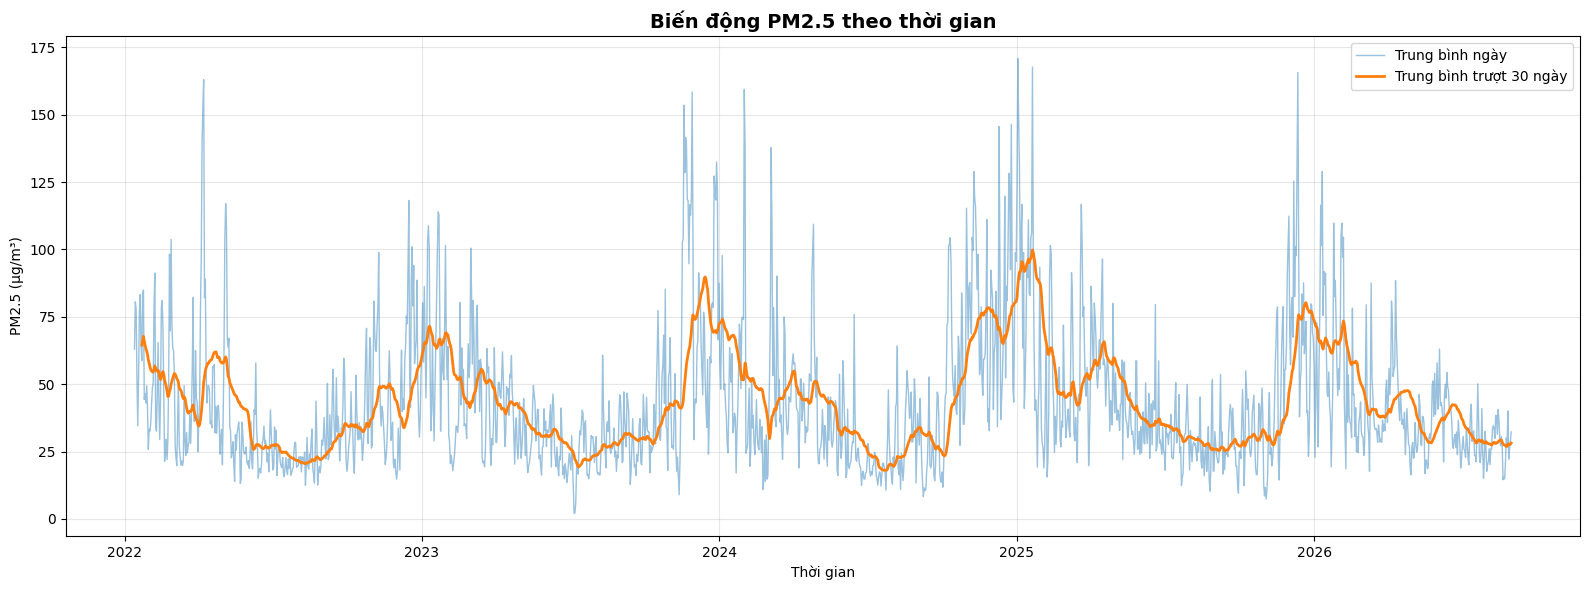

In [11]:
daily_pm25 = ts['PM25'].resample('D').mean()
monthly_pm25 = ts['PM25'].resample('MS').mean()

plt.figure(figsize=(16, 6))
plt.plot(daily_pm25.index, daily_pm25.values, alpha=0.45, linewidth=1, label='Trung bình ngày')
plt.plot(daily_pm25.rolling(30, min_periods=10).mean(), linewidth=2, label='Trung bình trượt 30 ngày')

plt.title('Biến động PM2.5 theo thời gian', fontsize=14, fontweight='bold')
plt.xlabel('Thời gian')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.1 Median và IQR theo tháng

In [12]:
month_profile = pd.DataFrame({'month': ts.index.month, 'PM25': ts['PM25'].values}).dropna()
month_stats = month_profile.groupby('month')['PM25'].agg(
    median='median',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    mean='mean'
)

display(month_stats)


,median,q25,q75,mean
month,,,,
1,56.900,39.000,84.900,66.394
2,35.400,26.000,52.500,45.004
3,37.600,28.000,56.000,45.764
4,43.400,33.300,58.775,50.994
5,30.000,21.500,40.000,34.639
6,26.000,18.000,38.000,30.831
7,23.000,16.100,31.300,24.850
8,24.300,17.200,34.400,27.084
9,26.300,18.000,37.400,29.509


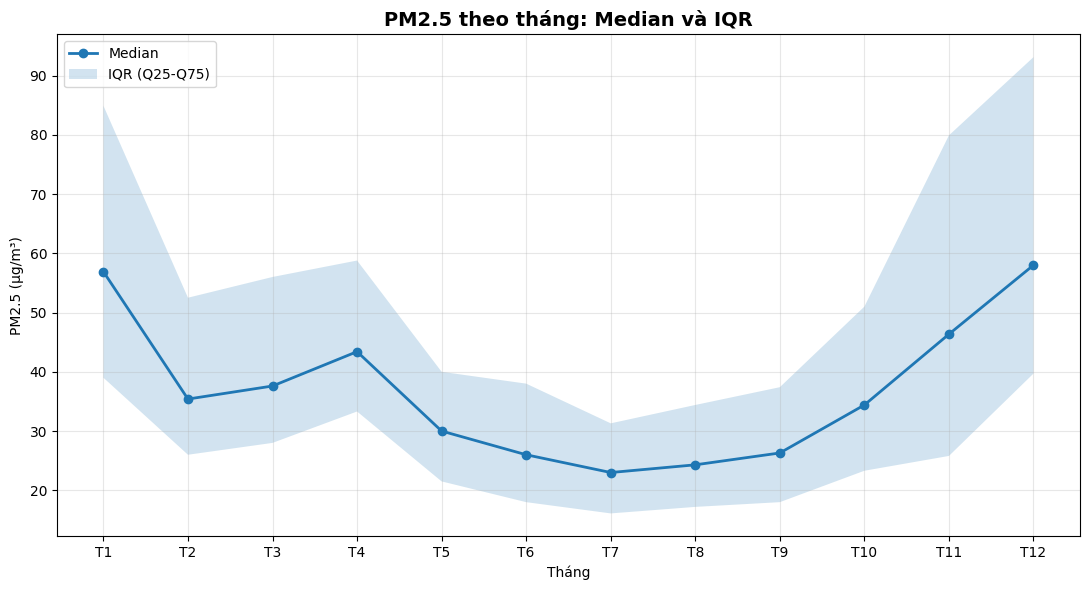

In [13]:
plt.figure(figsize=(11, 6))

plt.plot(month_stats.index, month_stats['median'], marker='o', linewidth=2, label='Median')

plt.fill_between(month_stats.index, month_stats['q25'], month_stats['q75'], alpha=0.2, label='IQR (Q25-Q75)')

plt.xticks(range(1, 13), [f'T{i}' for i in range(1, 13)])
plt.title('PM2.5 theo tháng: Median và IQR', fontsize=14, fontweight='bold')
plt.xlabel('Tháng')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Dùng median + IQR giúp hạn chế việc các peak rất cao kéo mean lên và cho thấy cả mức điển hình lẫn độ phân tán của PM2.5.


**Nhận xét.** Chu kỳ mùa rất rõ. Tháng 12 và tháng 1 có median cao nhất (58.0 và 56.9 µg/m³),
tháng 7 thấp nhất (23.0). Chênh giữa đỉnh và đáy khoảng 2.5 lần.

Đáng chú ý là IQR mùa đông rộng hơn hẳn mùa hè, nghĩa là mùa đông không chỉ cao hơn mà còn khó đoán hơn.
Vì vậy biến thời gian dạng tuần hoàn theo tháng là bắt buộc, và sai số mô hình nên được tách riêng theo mùa.

# VI. PM2.5 có quy luật theo giờ, ngày và mùa không?

In [14]:
eda_time = ts[['PM25']].copy()

eda_time['Hour'] = eda_time.index.hour
eda_time['DayOfWeek'] = eda_time.index.dayofweek
eda_time['Month'] = eda_time.index.month
eda_time['Year'] = eda_time.index.year

def get_season(month):
    if month in [12, 1, 2]:
        return 'Đông'
    elif month in [3, 4, 5]:
        return 'Xuân'
    elif month in [6, 7, 8]:
        return 'Hạ'
    return 'Thu'

eda_time['Season'] = eda_time['Month'].apply(get_season)

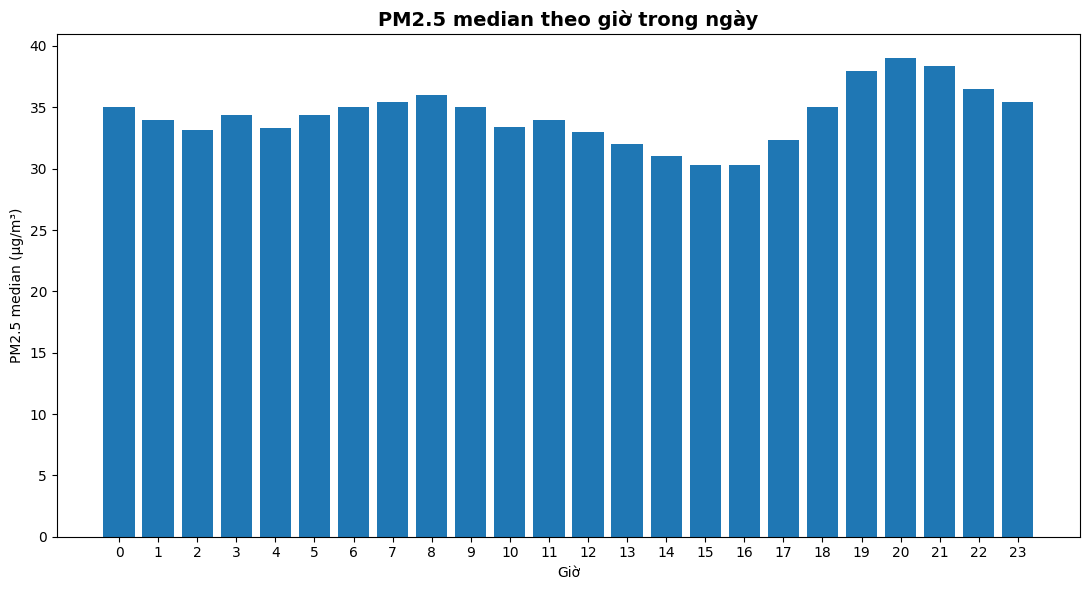

In [15]:
hourly_pm25 = eda_time.groupby('Hour')['PM25'].median()

plt.figure(figsize=(11, 6))
bars = plt.bar(hourly_pm25.index, hourly_pm25.values)

plt.title('PM2.5 median theo giờ trong ngày', fontsize=14, fontweight='bold')
plt.xlabel('Giờ')
plt.ylabel('PM2.5 median (µg/m³)')
plt.xticks(range(24))
plt.tight_layout()
plt.show()


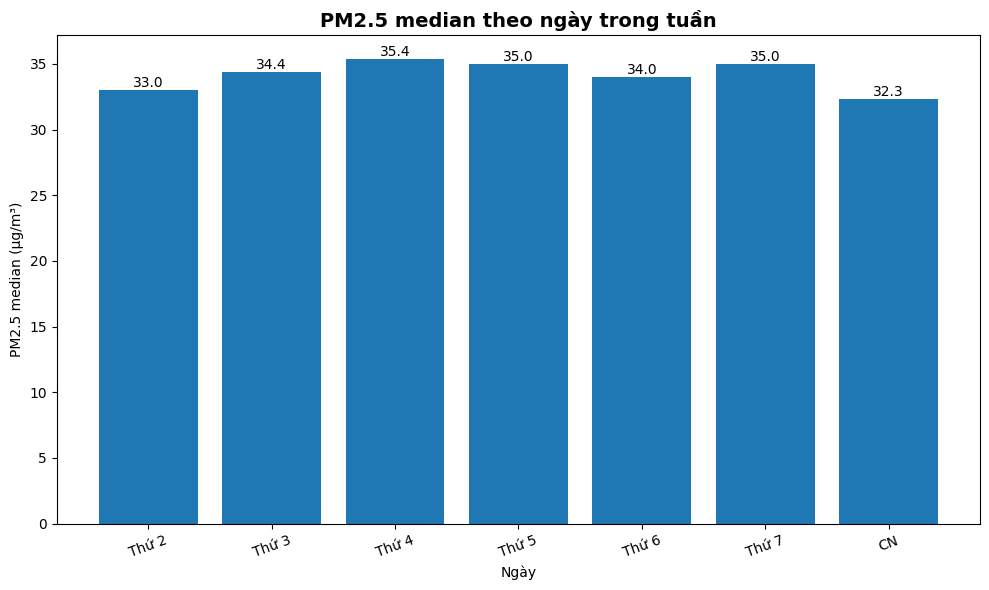

In [16]:
day_names = ['Thứ 2', 'Thứ 3', 'Thứ 4', 'Thứ 5', 'Thứ 6', 'Thứ 7', 'CN']

dow_pm25 = eda_time.groupby('DayOfWeek')['PM25'].median()
dow_pm25.index = day_names

plt.figure(figsize=(10, 6))
bars = plt.bar(dow_pm25.index, dow_pm25.values)

plt.title('PM2.5 median theo ngày trong tuần', fontsize=14, fontweight='bold')
plt.xlabel('Ngày')
plt.ylabel('PM2.5 median (µg/m³)')
plt.xticks(rotation=20)

for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:
weekday_median = eda_time.loc[eda_time['DayOfWeek'] < 5, 'PM25'].median()
weekend_median = eda_time.loc[eda_time['DayOfWeek'] >= 5, 'PM25'].median()

print(f'Chênh giữa ngày cao nhất và thấp nhất: {dow_pm25.max() - dow_pm25.min():.1f} µg/m³')
print(f'Ngày thường: {weekday_median:.1f} | Cuối tuần: {weekend_median:.1f}')

**Cách đọc kết quả.** So chênh lệch giữa các ngày trong tuần với chênh theo giờ (hàng chục µg/m³) và theo mùa
(Đông 49.0 so với Hạ 24.2). Nếu chênh theo ngày trong tuần chỉ vài µg/m³ thì chu kỳ tuần yếu,
`dow_sin/cos` chỉ là biến phụ và bước chọn đặc trưng có thể bỏ được mà không mất gì.

,mean,median
Season,,
Xuân,43.721,36.500
Hạ,27.553,24.200
Thu,43.742,33.300
Đông,60.324,49.000


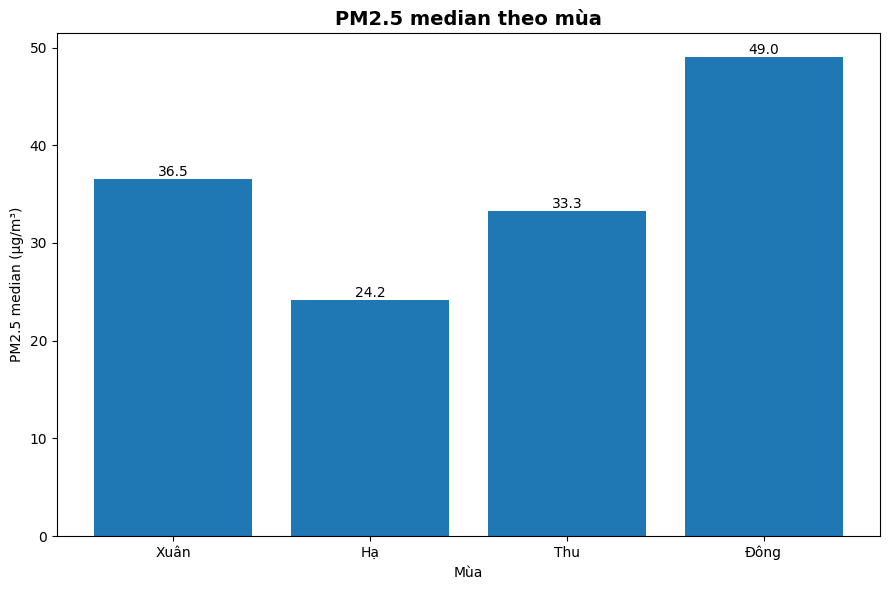

In [17]:
season_order = ['Xuân', 'Hạ', 'Thu', 'Đông']

season_stats = eda_time.groupby('Season')['PM25'].agg(mean='mean', median='median').reindex(season_order)

display(season_stats)

plt.figure(figsize=(9, 6))
bars = plt.bar(season_stats.index, season_stats['median'])

plt.title('PM2.5 median theo mùa', fontsize=14, fontweight='bold')
plt.xlabel('Mùa')
plt.ylabel('PM2.5 median (µg/m³)')

for bar in bars:
    value = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, value, f'{value:.1f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

## 6.1 Heatmap Hour × Month

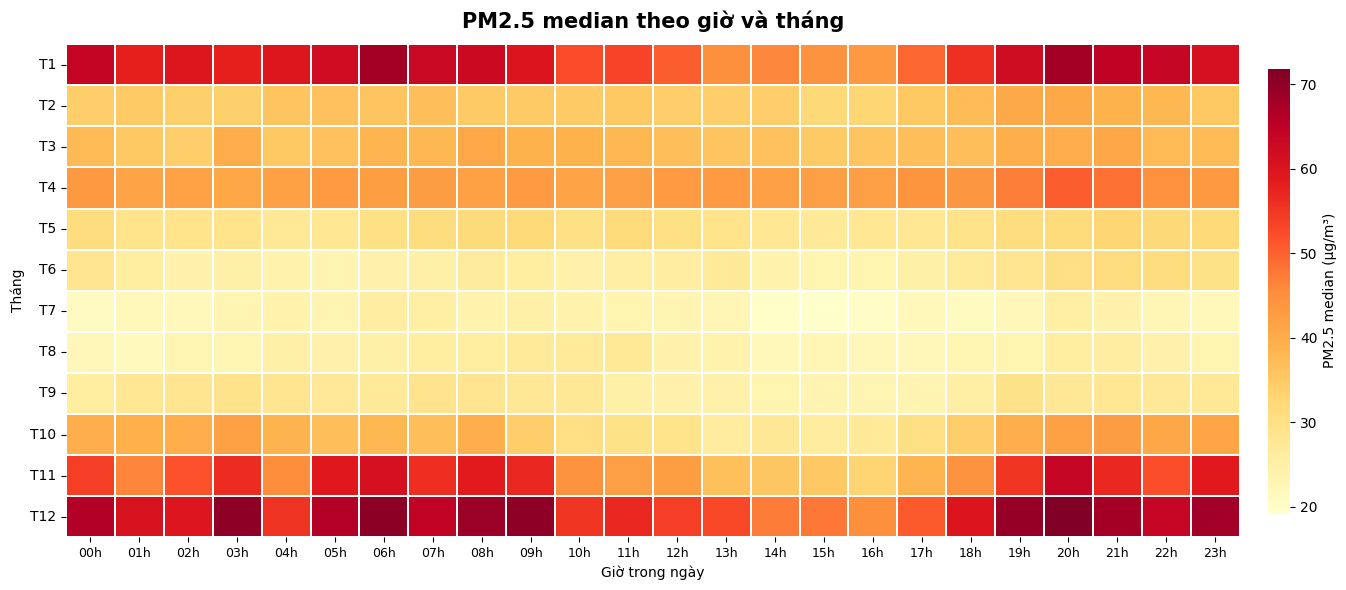

In [18]:
hour_month = eda_time.pivot_table(index='Month', columns='Hour', values='PM25', aggfunc='median')

plt.figure(figsize=(15, 6))
ax = sns.heatmap(hour_month, cmap='YlOrRd', linewidths=0.35, linecolor='white',
                 cbar_kws={'label': 'PM2.5 median (µg/m³)', 'shrink': 0.9, 'pad': 0.02})

ax.set_title('PM2.5 median theo giờ và tháng', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Giờ trong ngày')
ax.set_ylabel('Tháng')
ax.set_xticklabels([f'{h:02d}h' for h in hour_month.columns], rotation=0, fontsize=9)
ax.set_yticklabels([f'T{m}' for m in hour_month.index], rotation=0)

plt.tight_layout()
plt.show()


## 6.2 Xác suất gặp PM2.5 cao theo giờ và tháng

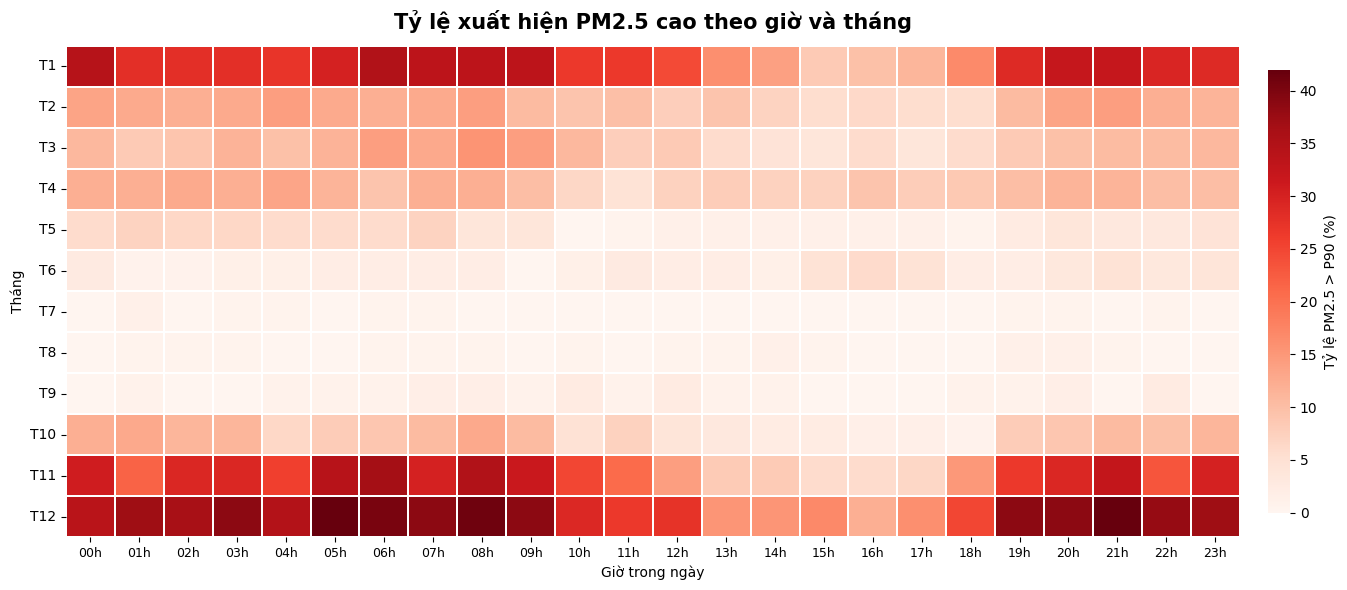

In [19]:
high_threshold = pm25.quantile(0.90)

high_pattern = eda_time.copy()
high_pattern['High_PM25'] = high_pattern['PM25'] > high_threshold
high_rate = high_pattern.pivot_table(index='Month', columns='Hour', values='High_PM25', aggfunc='mean') * 100

plt.figure(figsize=(15, 6))
ax = sns.heatmap(high_rate, cmap='Reds', linewidths=0.35, linecolor='white',
                 cbar_kws={'label': 'Tỷ lệ PM2.5 > P90 (%)', 'shrink': 0.9, 'pad': 0.02})

ax.set_title('Tỷ lệ xuất hiện PM2.5 cao theo giờ và tháng', fontsize=15, fontweight='bold', pad=12)
ax.set_xlabel('Giờ trong ngày')
ax.set_ylabel('Tháng')
ax.set_xticklabels([f'{h:02d}h' for h in high_rate.columns], rotation=0, fontsize=9)
ax.set_yticklabels([f'T{m}' for m in high_rate.index], rotation=0)

plt.tight_layout()
plt.show()


**Nhận xét.** Có hai quy luật chồng lên nhau: chu kỳ ngày (đỉnh quanh giờ cao điểm sáng và tối)
và chu kỳ mùa (nền cao suốt tháng 11 đến tháng 2).

Hệ quả cho bước sau: cần cả biến giờ trong ngày và biến tháng, đồng thời xem xét tương tác giữa hai chiều này
chứ không chỉ cộng hai hiệu ứng lại.

## 6.3 Ngày lễ có làm PM2.5 thay đổi không

Notebook 05 tạo cờ `IsHoliday` với giả định ngày lễ làm giảm giao thông. Giả định này cần được kiểm tra ở đây.
Để công bằng, mỗi ngày lễ chỉ so với **ngày thường cùng tháng cùng năm**, vì Tết rơi vào mùa đông
nên so với cả năm sẽ thấy PM2.5 ngày lễ cao chỉ do mùa.

In [ ]:
VN_HOLIDAYS = {
    # Tết Dương lịch
    '2022-01-01', '2023-01-01', '2024-01-01', '2025-01-01', '2026-01-01',
    # Giỗ Tổ Hùng Vương
    '2022-04-10', '2023-04-29', '2024-04-18', '2025-04-07', '2026-04-26',
    # 30/4 - 1/5
    '2022-04-30', '2022-05-01', '2023-04-30', '2023-05-01',
    '2024-04-30', '2024-05-01', '2025-04-30', '2025-05-01',
    '2026-04-30', '2026-05-01',
    # Quốc khánh 2/9 (2022 nghỉ 1-4/9)
    '2022-09-01', '2022-09-02', '2022-09-03', '2022-09-04',
    '2023-09-01', '2023-09-02', '2023-09-03',
    '2024-08-31', '2024-09-01', '2024-09-02', '2024-09-03',
    '2025-08-30', '2025-08-31', '2025-09-01', '2025-09-02',
    '2026-08-31', '2026-09-01', '2026-09-02',
    # Tết Nguyên Đán
    '2022-01-29', '2022-01-30', '2022-01-31', '2022-02-01', '2022-02-02',
    '2022-02-03', '2022-02-04', '2022-02-05', '2022-02-06',
    '2023-01-20', '2023-01-21', '2023-01-22', '2023-01-23', '2023-01-24',
    '2023-01-25', '2023-01-26',
    '2024-02-08', '2024-02-09', '2024-02-10', '2024-02-11', '2024-02-12',
    '2024-02-13', '2024-02-14',
    '2025-01-25', '2025-01-26', '2025-01-27', '2025-01-28', '2025-01-29',
    '2025-01-30', '2025-01-31', '2025-02-01', '2025-02-02',
    '2026-02-14', '2026-02-15', '2026-02-16', '2026-02-17', '2026-02-18',
    '2026-02-19', '2026-02-20', '2026-02-21', '2026-02-22',
}

holiday_df = eda_time[['PM25', 'Year', 'Month']].copy()
holiday_df['IsHoliday'] = holiday_df.index.strftime('%Y-%m-%d').isin(VN_HOLIDAYS)

# Chỉ giữ các tháng có ngày lễ, so median ngày lễ với median ngày thường cùng tháng
holiday_cmp = (holiday_df.groupby(['Year', 'Month', 'IsHoliday'])['PM25']
               .median().unstack('IsHoliday').dropna())
holiday_cmp.columns = ['Ngày thường', 'Ngày lễ']
holiday_cmp['Chênh (lễ - thường)'] = holiday_cmp['Ngày lễ'] - holiday_cmp['Ngày thường']

display(holiday_cmp.round(1))
print('Số tháng có ngày lễ:', len(holiday_cmp))
print('Số tháng ngày lễ thấp hơn ngày thường:', int((holiday_cmp['Chênh (lễ - thường)'] < 0).sum()))
print(f"Trung vị chênh lệch: {holiday_cmp['Chênh (lễ - thường)'].median():.1f} µg/m³")

**Cách đọc kết quả.** Nếu phần lớn các tháng có ngày lễ thấp hơn ngày thường và trung vị chênh lệch âm rõ,
giả định "ngày lễ giảm giao thông nên giảm bụi" có cơ sở và `IsHoliday` đáng giữ.
Nếu chênh lệch đổi dấu lung tung giữa các năm thì hiệu ứng ngày lễ bị thời tiết lấn át,
và cần ghi rõ điều này thay vì gọi `IsHoliday` là insight từ EDA.
Riêng Tết Nguyên Đán còn có đốt vàng mã và pháo hoa, nên hiệu ứng có thể ngược với các ngày lễ khác.

# VII. PM2.5 phụ thuộc vào lịch sử của chính nó bao lâu?

In [20]:
lags_check = [1, 3, 6, 12, 24, 48, 72, 168]

acf_rows = []

for lag in lags_check:
    acf_rows.append({'Lag_hour': lag, 'Autocorrelation': ts['PM25'].autocorr(lag=lag)})

acf_table = pd.DataFrame(acf_rows)
display(acf_table)

,Lag_hour,Autocorrelation
0,1,0.881
1,3,0.766
2,6,0.639
3,12,0.520
4,24,0.589
5,48,0.455
6,72,0.378
7,168,0.263


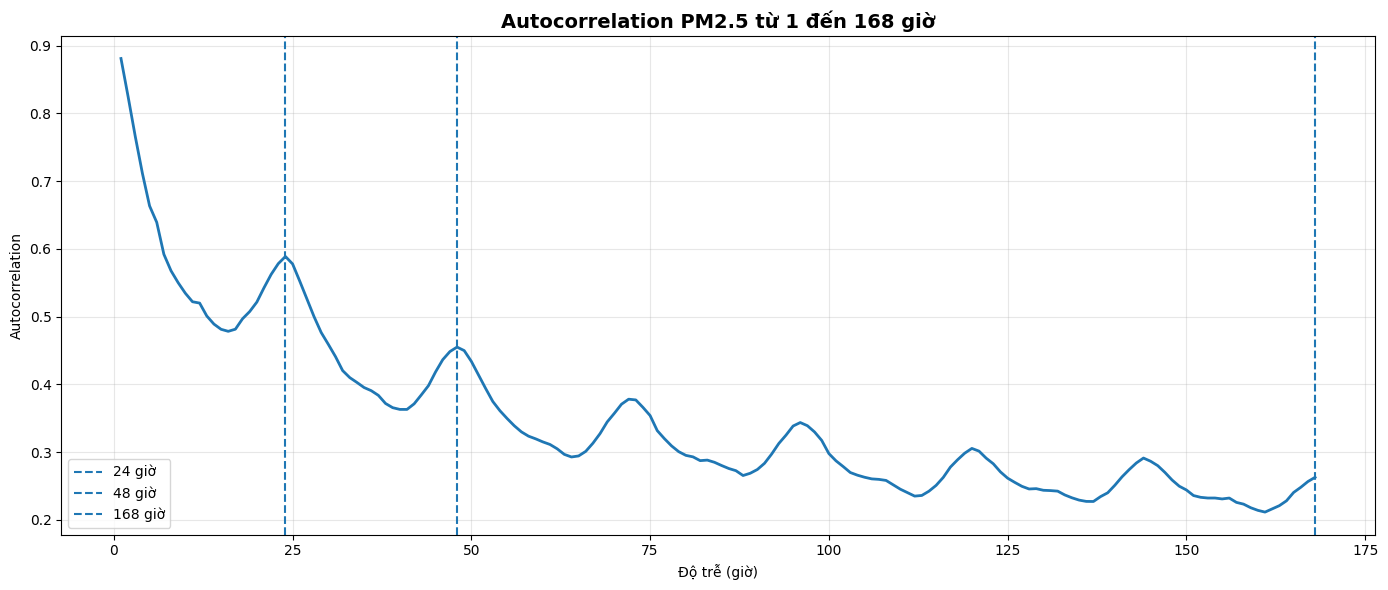

In [21]:
acf_all = []

for lag in range(1, 169):
    acf_all.append(ts['PM25'].autocorr(lag=lag))

plt.figure(figsize=(14, 6))
plt.plot(range(1, 169), acf_all, linewidth=2)

plt.axvline(24, linestyle='--', label='24 giờ')
plt.axvline(48, linestyle='--', label='48 giờ')
plt.axvline(168, linestyle='--', label='168 giờ')

plt.title('Autocorrelation PM2.5 từ 1 đến 168 giờ',
          fontsize=14, fontweight='bold')
plt.xlabel('Độ trễ (giờ)')
plt.ylabel('Autocorrelation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Nhận xét.** Tương quan với chính nó giảm dần nhưng không mất hẳn:
lag 1 giờ còn 0.88, lag 24 giờ còn 0.59, lag 168 giờ (một tuần) vẫn còn 0.26.

Hai điều rút ra.

Thứ nhất, giá trị lag 24 giờ cao hơn lag 12 giờ cho thấy có chu kỳ ngày rõ, tức là chỉ dùng lag liên tiếp
sẽ bỏ sót phần "cùng giờ hôm qua".

Thứ hai, **chưa thể kết luận ngay là cần nhìn lại một tuần**. ACF ở đây tính trên chuỗi gốc,
mà chuỗi gốc có nền mùa đông cao kéo dài nhiều tháng. Con số 0.26 ở lag 168 giờ có thể phần lớn chỉ phản ánh
"tuần trước cũng là mùa đông", không phải thông tin dự báo. Mục 7.1 kiểm tra lại sau khi loại mùa vụ.

## 7.1 ACF sau khi loại mùa vụ và chu kỳ ngày

Trừ median theo từng cặp (tháng, giờ) để bỏ phần lặp lại theo mùa và theo giờ, rồi tính lại ACF.
Phần còn lại là "trí nhớ" thật của chuỗi ngoài những gì lịch đã cho biết.

In [ ]:
pm25_anom = ts['PM25'] - ts.groupby([ts.index.month, ts.index.hour])['PM25'].transform('median')

acf_compare = pd.DataFrame({
    'Lag_hour': lags_check,
    'ACF_goc': [ts['PM25'].autocorr(lag=l) for l in lags_check],
    'ACF_sau_loai_mua': [pm25_anom.autocorr(lag=l) for l in lags_check],
})
display(acf_compare.round(3))

acf_anom_all = [pm25_anom.autocorr(lag=l) for l in range(1, 169)]

plt.figure(figsize=(14, 6))
plt.plot(range(1, 169), acf_all, linewidth=2, label='Chuỗi gốc')
plt.plot(range(1, 169), acf_anom_all, linewidth=2, label='Sau khi trừ median (tháng, giờ)')
plt.axhline(0.1, linestyle=':', color='grey', label='Mốc 0.1')
for lag in (24, 48, 168):
    plt.axvline(lag, linestyle='--', color='grey', alpha=0.5)
plt.title('ACF trước và sau khi loại mùa vụ', fontsize=14, fontweight='bold')
plt.xlabel('Độ trễ (giờ)')
plt.ylabel('Autocorrelation')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

below = [l for l, v in zip(range(1, 169), acf_anom_all) if v < 0.1]
print('Lag đầu tiên ACF sau loại mùa xuống dưới 0.1:', below[0] if below else 'không xuống dưới 0.1 trong 168 giờ')

**Cách đọc kết quả.** Nếu ACF sau loại mùa tụt xuống gần 0 sau vài chục giờ thì phần "trí nhớ một tuần"
chủ yếu đến từ mùa vụ. Khi đó cửa sổ lookback 1–4 ngày là đủ, và mùa vụ nên được đưa vào mô hình bằng
biến lịch (`month_sin/cos`) chứ không bằng cách kéo dài cửa sổ. Điều này cũng giải thích vì sao ở notebook 06
các window 24, 48, 72, 96 giờ cho MAE gần như bằng nhau.

Vì vậy độ dài cửa sổ nên **chọn bằng thử nghiệm** (notebook 06), không suy thẳng từ ACF chuỗi gốc.

# VIII. Forecast horizon càng xa thì bài toán khó lên như thế nào?

In [22]:
horizons = [1, 3, 6, 12, 24, 48, 72]

forecast_rows = []

for h in horizons:
    diff = (ts['PM25'].shift(-h) - ts['PM25']).abs().dropna()

    forecast_rows.append({
        'Horizon_h': h,
        'Mean_abs_change': diff.mean(),
        'Median_abs_change': diff.median(),
        'P90_abs_change': diff.quantile(0.90)
    })

forecast_change = pd.DataFrame(forecast_rows)
display(forecast_change)


,Horizon_h,Mean_abs_change,Median_abs_change,P90_abs_change
0,1,8.154,4.000,18.300
1,3,13.058,7.100,30.300
2,6,16.989,10.000,40.000
3,12,20.146,12.000,48.000
4,24,18.931,11.800,44.100
5,48,22.567,14.200,52.600
6,72,24.288,15.200,57.000


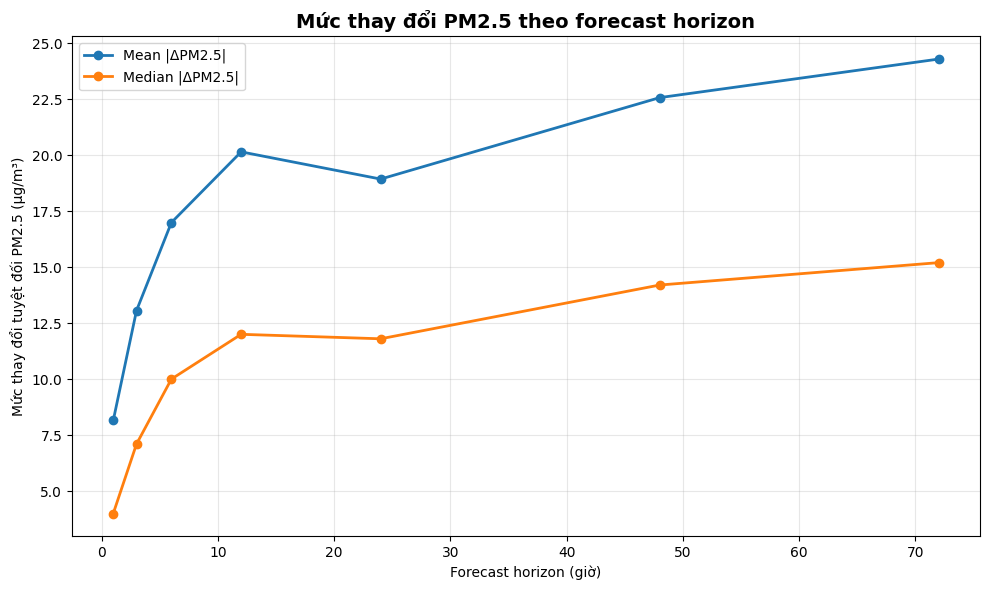

In [23]:
plt.figure(figsize=(10, 6))

plt.plot(forecast_change['Horizon_h'], forecast_change['Mean_abs_change'], marker='o', linewidth=2, label='Mean |ΔPM2.5|')

plt.plot(forecast_change['Horizon_h'], forecast_change['Median_abs_change'], marker='o', linewidth=2, label='Median |ΔPM2.5|')

plt.title('Mức thay đổi PM2.5 theo forecast horizon', fontsize=14, fontweight='bold')
plt.xlabel('Forecast horizon (giờ)')
plt.ylabel('Mức thay đổi tuyệt đối PM2.5 (µg/m³)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Nhận xét.** Mức thay đổi PM2.5 tăng nhanh từ 1 giờ (8.2) sang 3 giờ (13.1), sau đó chậm lại
(12 giờ 20.1, 24 giờ 18.9).

Nghĩa là các giờ đầu quyết định phần lớn độ khó của bài toán. Cũng vì thế không nên báo cáo một con số MAE duy nhất
cho mọi horizon, mà phải tách riêng từng mốc dự báo.

Đáng chú ý là horizon 24 giờ **dễ hơn** 12 giờ (18.9 so với 20.1). Lý do là chu kỳ ngày:
sau 24 giờ PM2.5 quay về đúng pha của chu kỳ, còn sau 12 giờ thì rơi vào pha ngược lại.
Khi so mô hình với Persistence, MAE ở 24 giờ thấp hơn ở 12 giờ là bình thường, không phải lỗi.

# IX. Các chất ô nhiễm khác có chứa thông tin cho PM2.5 tương lai không?

In [24]:
pollutants = ['PM10', 'CO', 'NO2', 'SO2', 'O3']

same_corr = (
    ts[pollutants + ['PM25']]
    .corr(method='spearman')['PM25']
    .drop('PM25')
    .sort_values(key=abs, ascending=False)
)

display(same_corr.to_frame('Spearman_same_time'))


,Spearman_same_time
PM10,0.953
NO2,0.195
SO2,0.192
CO,0.115
O3,-0.042


In [25]:
future_horizons = [3, 6, 12, 24]

pollutant_future_corr = pd.DataFrame(
    index=pollutants,
    columns=[f'+{h}h' for h in future_horizons],
    dtype=float
)

for col in pollutants:
    for h in future_horizons:
        temp = pd.concat(
            [ts[col], ts['PM25'].shift(-h)],
            axis=1
        ).dropna()

        temp.columns = ['X', 'PM25_future']

        pollutant_future_corr.loc[col, f'+{h}h'] = (
            temp['X'].corr(temp['PM25_future'], method='spearman')
        )

display(pollutant_future_corr.round(3))


,+3h,+6h,+12h,+24h
PM10,0.755,0.653,0.555,0.566
CO,0.116,0.084,0.068,0.084
NO2,0.178,0.128,0.096,0.133
SO2,0.186,0.178,0.152,0.158
O3,-0.013,0.020,0.025,-0.041


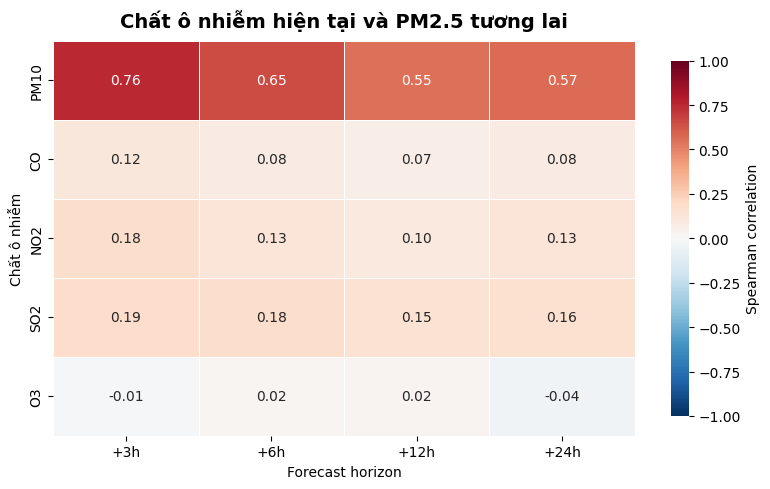

In [26]:
plt.figure(figsize=(8, 5))
ax = sns.heatmap(pollutant_future_corr.astype(float), annot=True, fmt='.2f', cmap='RdBu_r',
                 center=0, vmin=-1, vmax=1, linewidths=0.5,
                 cbar_kws={'label': 'Spearman correlation', 'shrink': 0.9})

ax.set_title('Chất ô nhiễm hiện tại và PM2.5 tương lai', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Forecast horizon')
ax.set_ylabel('Chất ô nhiễm')

plt.tight_layout()
plt.show()


**Nhận xét.** PM10 gần như đồng biến với PM2.5 tại cùng thời điểm (Spearman 0.95) và vẫn còn 0.76 ở +3 giờ.
Các chất còn lại yếu hơn nhiều, đều dưới 0.2.

Hệ quả: PM10 là đầu vào quan trọng nhất, đồng thời cũng là điểm yếu —
nếu dữ liệu PM10 bị lỗi hoặc thiếu thì mô hình mất phần lớn năng lực dự báo.
NO2 và SO2 góp thông tin về nguồn thải nên vẫn nên giữ, còn O3 có tương quan âm nhẹ.

Lưu ý thêm: nếu PM10 và PM2.5 cùng do một mô hình lưới sinh ra (xem mục 4.2 và XV),
tương quan 0.95 một phần là do cách tạo dữ liệu chứ không hoàn toàn là quan hệ vật lý.

# X. Khí tượng liên hệ với PM2.5 như thế nào?

## 10.1 Quan hệ cùng thời điểm

In [27]:
weather_cols = [
    'Temperature',
    'Relative Humidity',
    'Precipitation',
    'Clouds',
    'Pressure',
    'UV Index',
    'Wind Speed',
    'Solar Radiation'
]

weather_cols = [c for c in weather_cols if c in ts.columns]
weather_corr = (ts[weather_cols + ['PM25']] .corr(method='spearman')['PM25'] .drop('PM25') .sort_values(key=abs, ascending=False))

display(weather_corr.to_frame('Spearman_PM25'))


,Spearman_PM25
Pressure,0.362
Temperature,-0.321
Precipitation,-0.204
Wind Speed,-0.182
Solar Radiation,-0.091
Relative Humidity,-0.069
UV Index,-0.068
Clouds,-0.061


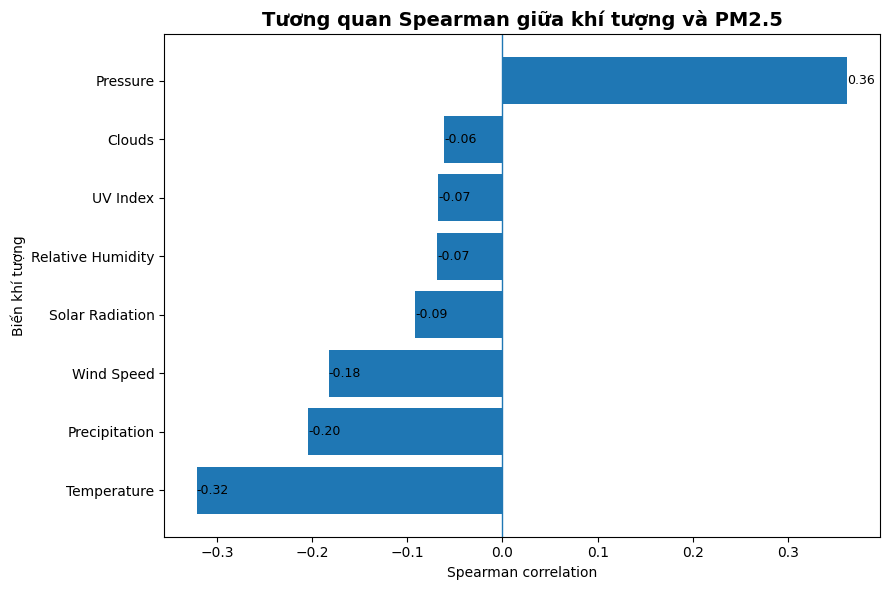

In [28]:
plt.figure(figsize=(9, 6))

ordered = weather_corr.sort_values()

plt.barh(ordered.index, ordered.values)
plt.axvline(0, linewidth=1)

for i, v in enumerate(ordered.values):
    plt.text(v, i, f'{v:.2f}', va='center', fontsize=9)
plt.title('Tương quan Spearman giữa khí tượng và PM2.5',
          fontsize=14, fontweight='bold')

plt.xlabel('Spearman correlation')
plt.ylabel('Biến khí tượng')
plt.tight_layout()
plt.show()


**Nhận xét.** Ở cùng thời điểm, áp suất là biến khí tượng tương quan dương mạnh nhất (0.36),
nhiệt độ âm mạnh nhất (-0.32), rồi tới mưa (-0.20) và tốc độ gió (-0.18).

Dấu của các quan hệ đúng với hiểu biết vật lý: áp cao đi kèm thời tiết ổn định và nghịch nhiệt nên bụi tích tụ,
nhiệt độ thấp cũng là điều kiện nghịch nhiệt mùa đông, mưa rửa bụi, gió làm loãng.
Tuy vậy phần 10.4 sẽ cho thấy không phải quan hệ nào cũng đứng vững khi loại bỏ mùa vụ.

## 10.2 Weather hiện tại có liên hệ với PM2.5 tương lai không?

In [29]:
weather_future_corr = pd.DataFrame(index=weather_cols, columns=[f'+{h}h' for h in future_horizons], dtype=float)

for col in weather_cols:
    for h in future_horizons:
        temp = pd.concat([ts[col], ts['PM25'].shift(-h)], axis=1).dropna()

        temp.columns = ['X', 'PM25_future']

        weather_future_corr.loc[col, f'+{h}h'] = (temp['X'].corr(temp['PM25_future'], method='spearman'))

display(weather_future_corr.round(3))

,+3h,+6h,+12h,+24h
Temperature,-0.319,-0.307,-0.319,-0.382
Relative Humidity,-0.089,-0.136,-0.178,-0.139
Precipitation,-0.216,-0.212,-0.201,-0.182
Clouds,-0.069,-0.073,-0.071,-0.051
Pressure,0.354,0.361,0.398,0.432
UV Index,-0.074,-0.023,0.043,-0.066
Wind Speed,-0.211,-0.192,-0.135,-0.142
Solar Radiation,-0.095,-0.045,0.023,-0.085


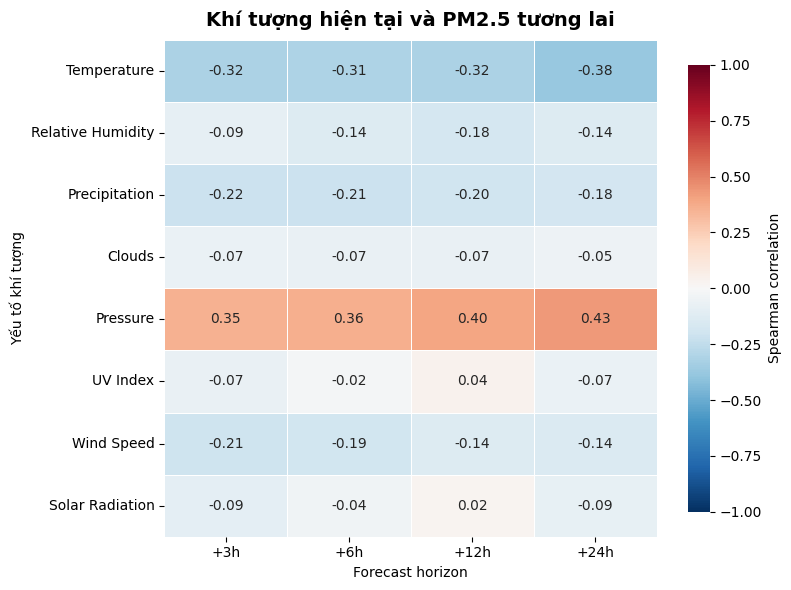

In [30]:
plt.figure(figsize=(8, 6))
ax = sns.heatmap(weather_future_corr.astype(float), annot=True, fmt='.2f', cmap='RdBu_r',
                 center=0, vmin=-1, vmax=1, linewidths=0.5,
                 cbar_kws={'label': 'Spearman correlation', 'shrink': 0.9})

ax.set_title('Khí tượng hiện tại và PM2.5 tương lai', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Forecast horizon')
ax.set_ylabel('Yếu tố khí tượng')

plt.tight_layout()
plt.show()


**Nhận xét.** Tương quan của khí tượng hiện tại với PM2.5 tương lai không yếu đi khi horizon dài ra,
thậm chí áp suất còn mạnh lên (0.35 ở +3 giờ, 0.43 ở +24 giờ).

Điều này hợp lý vì thời tiết biến đổi chậm hơn PM2.5. Nhưng nó cũng có nghĩa là thông tin khí tượng tại thời điểm dự báo
vẫn còn giá trị ở xa, trong khi thông tin nồng độ quá khứ thì mất dần.
Vì vậy biến khí tượng nên xuất hiện cả ở nhánh dự báo dài hạn, không chỉ ở bước đầu.

## 10.3 Quan hệ có dấu hiệu phi tuyến không?


 Wind Speed


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(-0.001, 1.0]",0.800,39.000,50.274,10115
"(1.0, 1.6]",1.330,38.700,50.882,6676
"(1.6, 2.0]",2.000,33.300,41.310,11625
"(2.0, 2.66]",2.360,31.000,36.923,5389
"(2.66, 28.33]",3.000,30.000,34.143,6803


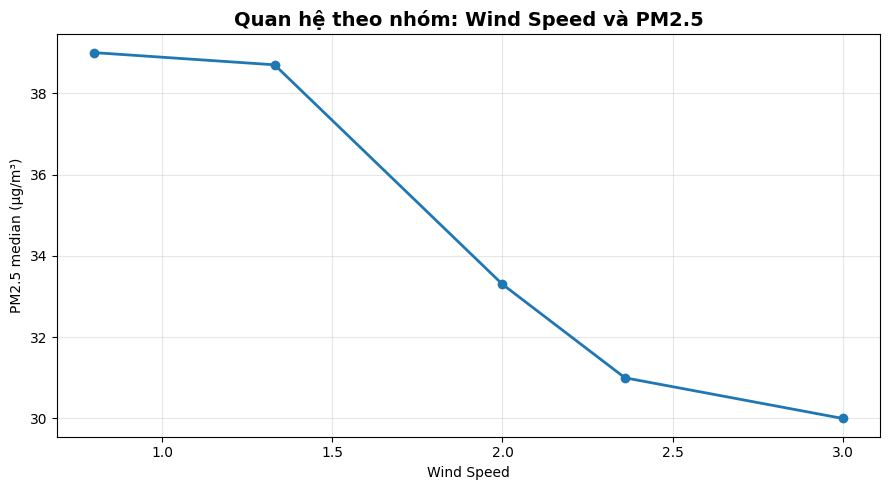


 Pressure


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(982.999, 1003.0]",1001.000,27.300,31.493,9589
"(1003.0, 1007.0]",1005.000,28.000,31.910,8131
"(1007.0, 1012.0]",1010.000,33.400,39.967,8336
"(1012.0, 1016.0]",1014.000,45.600,57.454,6507
"(1016.0, 1033.0]",1020.000,49.600,61.059,8045


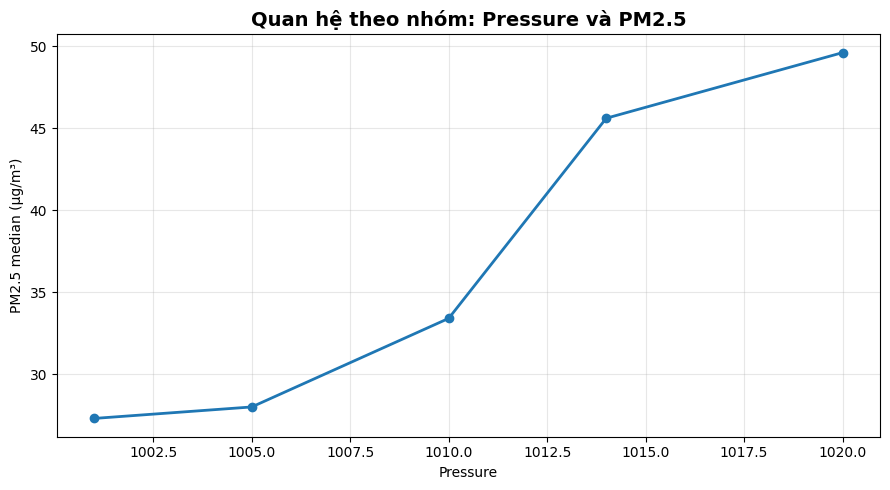


 Temperature


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(6.999, 20.0]",17.200,49.500,60.573,8283
"(20.0, 24.5]",22.500,41.400,53.381,8184
"(24.5, 27.1]",26.000,31.100,36.373,8116
"(27.1, 29.7]",28.400,29.000,32.613,8073
"(29.7, 41.1]",31.800,29.000,33.024,7952


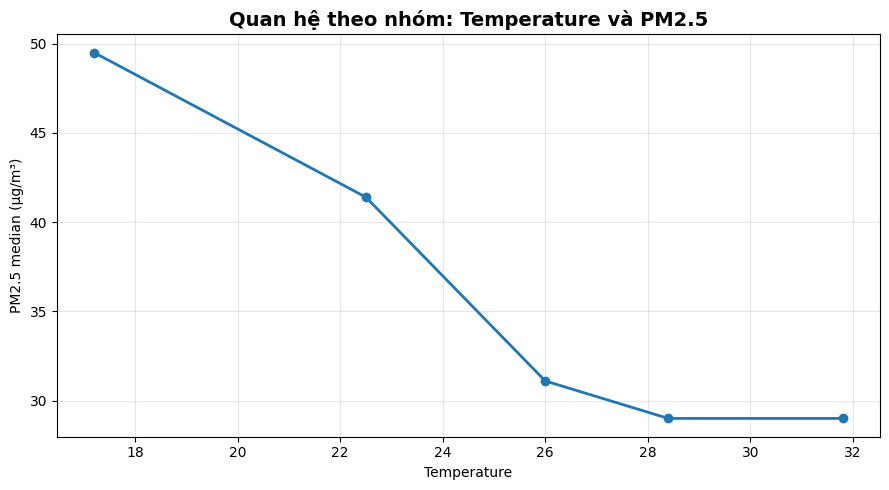


 Relative Humidity


,X_median,PM25_median,PM25_mean,N
Group,,,,
"(16.999, 66.0]",57.000,35.200,43.628,8628
"(66.0, 78.0]",73.000,36.000,45.446,8062
"(78.0, 87.0]",84.000,35.400,44.712,8760
"(87.0, 92.0]",90.000,33.000,41.737,7553
"(92.0, 100.0]",94.000,31.400,40.759,7605


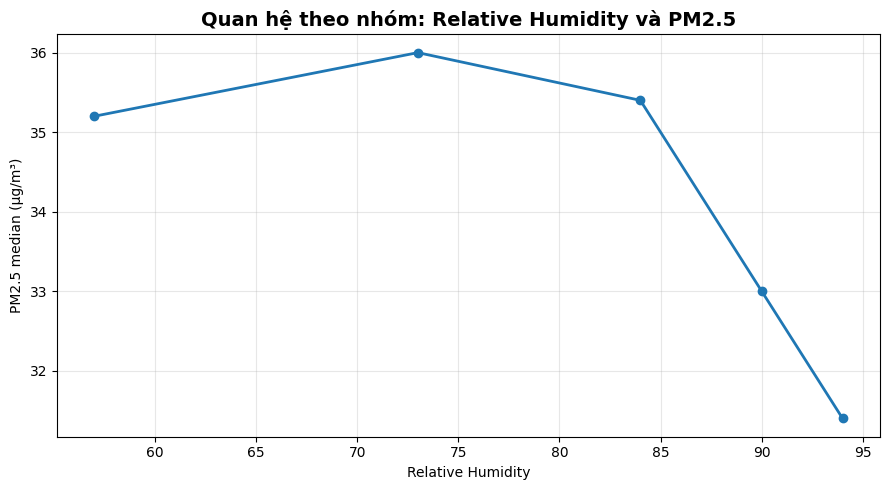

In [31]:
check_cols = [c for c in ['Wind Speed', 'Pressure', 'Temperature', 'Relative Humidity'] if c in ts.columns]

for col in check_cols:
    temp = ts[[col, 'PM25']].dropna().copy()

    temp['Group'] = pd.qcut(temp[col], q=5, duplicates='drop')

    summary = temp.groupby(
        'Group',
        observed=False
    ).agg(
        X_median=(col, 'median'),
        PM25_median=('PM25', 'median'),
        PM25_mean=('PM25', 'mean'),
        N=('PM25', 'size')
    )

    print('\n', col)
    display(summary)

    plt.figure(figsize=(9, 5))
    plt.plot(summary['X_median'], summary['PM25_median'], marker='o', linewidth=2)

    plt.title(f'Quan hệ theo nhóm: {col} và PM2.5', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('PM2.5 median (µg/m³)')
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Nếu PM2.5 thay đổi gần đều khi X tăng thì quan hệ có xu hướng gần tuyến tính. Nếu độ dốc thay đổi mạnh, bão hòa hoặc đổi chiều thì có dấu hiệu phi tuyến.


## 10.4 Correlation sau khi giảm ảnh hưởng mùa vụ

In [32]:
# Tạo anomaly bằng cách trừ median của từng tháng trong năm
anomaly_cols = ['PM25'] + weather_cols
anomaly_df = ts[anomaly_cols].copy()

month_number = anomaly_df.index.month

for col in anomaly_cols:
    monthly_median = anomaly_df.groupby(month_number)[col].transform('median')
    anomaly_df[col + '_anom'] = anomaly_df[col] - monthly_median

anomaly_corr = {}

for col in weather_cols:
    temp = anomaly_df[[col + '_anom', 'PM25_anom']].dropna()
    anomaly_corr[col] = temp[col + '_anom'].corr(temp['PM25_anom'], method='spearman')

anomaly_corr = pd.Series(anomaly_corr).sort_values(key=abs, ascending=False)

comparison_corr = pd.DataFrame({'Corr_goc': weather_corr, 'Corr_sau_khi_tru_median_thang': anomaly_corr})

display(comparison_corr.round(3))

,Corr_goc,Corr_sau_khi_tru_median_thang
Clouds,-0.061,-0.139
Precipitation,-0.204,-0.082
Pressure,0.362,0.013
Relative Humidity,-0.069,-0.007
Solar Radiation,-0.091,-0.044
Temperature,-0.321,0.021
UV Index,-0.068,-0.035
Wind Speed,-0.182,-0.234


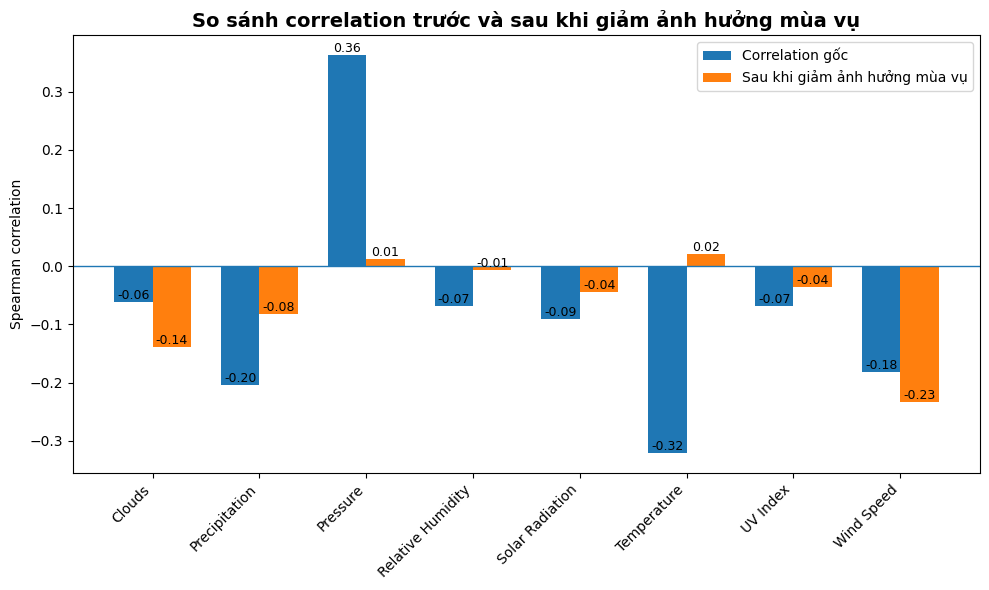

In [33]:
plt.figure(figsize=(10, 6))

x = np.arange(len(comparison_corr.index))
width = 0.36

plt.bar(x - width/2, comparison_corr['Corr_goc'], width=width, label='Correlation gốc')

plt.bar(x + width/2, comparison_corr['Corr_sau_khi_tru_median_thang'], width=width, label='Sau khi giảm ảnh hưởng mùa vụ')

for i, v in enumerate(comparison_corr['Corr_goc']):
    plt.text(i - width/2, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

for i, v in enumerate(comparison_corr['Corr_sau_khi_tru_median_thang']):
    plt.text(i + width/2, v, f'{v:.2f}', ha='center', va='bottom', fontsize=9)

plt.axhline(0, linewidth=1)
plt.xticks(x, comparison_corr.index, rotation=45, ha='right')
plt.ylabel('Spearman correlation')
plt.title('So sánh correlation trước và sau khi giảm ảnh hưởng mùa vụ', fontsize=14, fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

Nếu correlation giảm mạnh sau khi trừ pattern theo tháng, một phần quan hệ ban đầu có thể đến từ việc hai biến cùng thay đổi theo mùa. Phần này giúp tránh diễn giải correlation quá đơn giản.


**Nhận xét.** Đây là phần quan trọng nhất của chương này.

Sau khi trừ median từng tháng, tương quan của áp suất giảm từ 0.362 xuống 0.013, của nhiệt độ từ -0.321 xuống +0.021.
Nghĩa là phần lớn "tác dụng" của hai biến này thực chất chỉ là chúng cùng thay đổi theo mùa với PM2.5,
không phải quan hệ nhân quả trực tiếp.

Ngược lại tốc độ gió mạnh lên (-0.182 thành -0.234) và mây cũng rõ hơn, cho thấy đây mới là các biến có tác dụng độc lập.
Khi diễn giải kết quả mô hình cần phân biệt rõ hai loại: biến mùa và biến cơ chế.

## 10.4b Kiểm tra lại trên phần đầu chuỗi và kiểm tra áp suất đổi nhanh

Hai việc:

1. Tính lại bảng 10.4 chỉ trên **70% đầu chuỗi** (tương ứng phần Train ở các bước sau),
   để chắc kết luận "áp suất và nhiệt độ là biến mùa, gió là biến cơ chế" không phụ thuộc vào giai đoạn Test.
2. Notebook 05 tạo `Pressure_anom_24` (áp suất giờ trước trừ trung bình 24 giờ trước đó) với giả thuyết
   áp suất tăng nhanh báo hiệu thời tiết ổn định và nghịch nhiệt. Giả thuyết này chưa được kiểm tra,
   nên ở đây đo tương quan của nó với PM2.5 tương lai sau khi đã loại mùa vụ.

In [ ]:
# 1. Bảng 10.4 trên 70% đầu chuỗi
train_part = anomaly_df.iloc[:int(len(anomaly_df) * 0.70)].copy()
month_train = train_part.index.month
for col in anomaly_cols:
    train_part[col + '_anom'] = train_part[col] - train_part.groupby(month_train)[col].transform('median')

anomaly_corr_train = pd.Series({
    col: train_part[col + '_anom'].corr(train_part['PM25_anom'], method='spearman')
    for col in weather_cols
})

robust_check = comparison_corr.copy()
robust_check['Sau_tru_mua_70%_dau'] = anomaly_corr_train
print('Từ', train_part.index.min(), 'đến', train_part.index.max())
display(robust_check.round(3))

# 2. Áp suất đổi nhanh và PM2.5 tương lai (đã loại mùa)
pressure_anom_24 = ts['Pressure'].shift(1) - ts['Pressure'].shift(1).rolling(24).mean()

pressure_rows = []
for h in [0] + future_horizons:
    pair = pd.concat([pressure_anom_24, anomaly_df['PM25_anom'].shift(-h)], axis=1).dropna()
    pressure_rows.append({'Horizon': f'+{h}h',
                          'Spearman': pair.iloc[:, 0].corr(pair.iloc[:, 1], method='spearman')})
display(pd.DataFrame(pressure_rows).round(3))

**Cách đọc kết quả.**

- Nếu cột `Sau_tru_mua_70%_dau` cùng dấu và cùng độ lớn với cột tính trên toàn chuỗi,
  kết luận ở 10.4 không phụ thuộc vào giai đoạn Test và có thể dùng an toàn.
- Nếu tương quan của `Pressure_anom_24` dương và lớn hơn khoảng 0.1 thì giả thuyết áp suất tăng nhanh
  báo hiệu bụi tích tụ có số liệu ủng hộ. Nếu gần 0 thì feature này không có cơ sở từ EDA,
  và phần mô tả ở notebook 05 cần ghi là giả thuyết.

## 10.5 Mưa cần phân tích riêng

,N,Rain_median,PM25_median,PM25_mean
Rain_group,,,,
Không mưa,31737,0.000,36.400,45.931
Mưa thấp,4091,0.500,29.300,36.587
Mưa vừa,2305,1.000,29.000,35.748
Mưa cao,2475,2.500,22.300,28.237


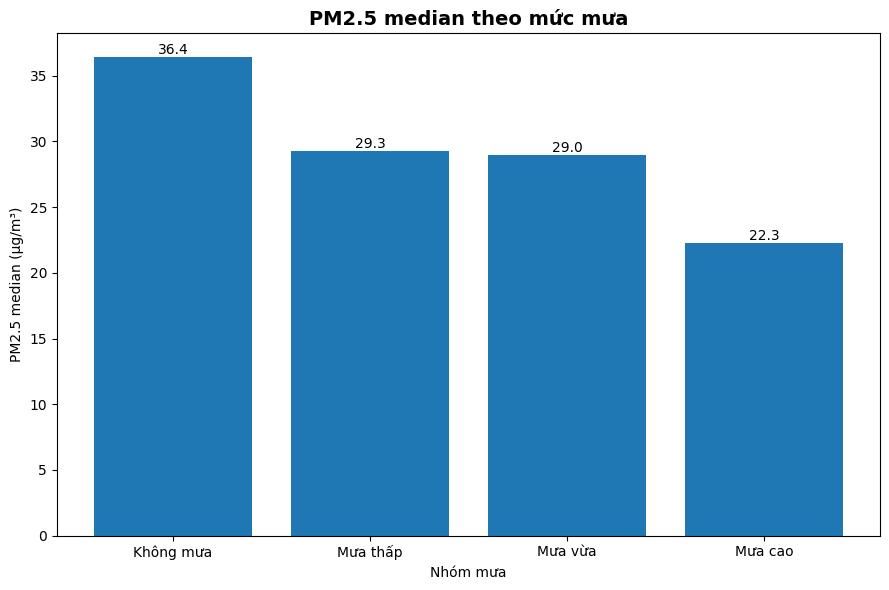

In [34]:
rain_data = ts[['Precipitation', 'PM25']].dropna().copy()

positive_rain = rain_data.loc[rain_data['Precipitation'] > 0, 'Precipitation']

if len(positive_rain) > 0:
    q1 = positive_rain.quantile(0.33)
    q2 = positive_rain.quantile(0.67)

    def rain_group(x):
        if x == 0:
            return 'Không mưa'
        elif x <= q1:
            return 'Mưa thấp'
        elif x <= q2:
            return 'Mưa vừa'
        return 'Mưa cao'

    rain_data['Rain_group'] = rain_data['Precipitation'].apply(rain_group)

    rain_summary = rain_data.groupby(
        'Rain_group'
    ).agg(
        N=('PM25', 'size'),
        Rain_median=('Precipitation', 'median'),
        PM25_median=('PM25', 'median'),
        PM25_mean=('PM25', 'mean')
    )

    order = ['Không mưa', 'Mưa thấp', 'Mưa vừa', 'Mưa cao']
    rain_summary = rain_summary.reindex([x for x in order if x in rain_summary.index])

    display(rain_summary)

    plt.figure(figsize=(9, 6))
    bars = plt.bar(rain_summary.index, rain_summary['PM25_median'])

    plt.title('PM2.5 median theo mức mưa', fontsize=14, fontweight='bold')
    plt.xlabel('Nhóm mưa')
    plt.ylabel('PM2.5 median (µg/m³)')

    for bar in bars:
        val = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, val, f'{val:.1f}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

**Nhận xét.** Mưa có tác dụng, nhưng phải đủ lớn mới thấy rõ:
không mưa 36.4, mưa nhẹ 0.5 mm chỉ còn 29.3, mưa từ 2.5 mm trở lên xuống 22.3 µg/m³.

Tức là mưa nhỏ làm ẩm và lắng bụi một phần, còn mưa lớn mới rửa sạch thực sự.
Vì vậy không nên dùng cờ "có mưa hay không", mà nên dùng cường độ mưa và số giờ đã trôi qua kể từ trận mưa cuối.

## 10.6 Hướng gió

In [35]:
wind_data = ts[['Wind Direction', 'Wind Speed', 'PM25']].dropna().copy()

direction_labels = np.array(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])

direction_index = (((wind_data['Wind Direction'] + 22.5) % 360) // 45).astype(int)

wind_data['Wind_sector'] = direction_labels[direction_index.values]

wind_sector_summary = wind_data.groupby('Wind_sector').agg(
    N=('PM25', 'size'),
    Wind_speed_median=('Wind Speed', 'median'),
    PM25_median=('PM25', 'median'),
    PM25_mean=('PM25', 'mean')
)

wind_order = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
wind_sector_summary = wind_sector_summary.reindex(wind_order)

display(wind_sector_summary)

,N,Wind_speed_median,PM25_median,PM25_mean
Wind_sector,,,,
N,5220,1.600,35.000,47.667
NE,3167,1.660,32.400,41.495
E,5263,2.000,35.000,43.736
SE,13250,2.000,34.400,41.851
S,5068,2.000,34.000,41.694
SW,1879,1.600,32.400,41.445
W,2002,1.330,35.000,44.319
NW,4759,1.830,34.400,45.564


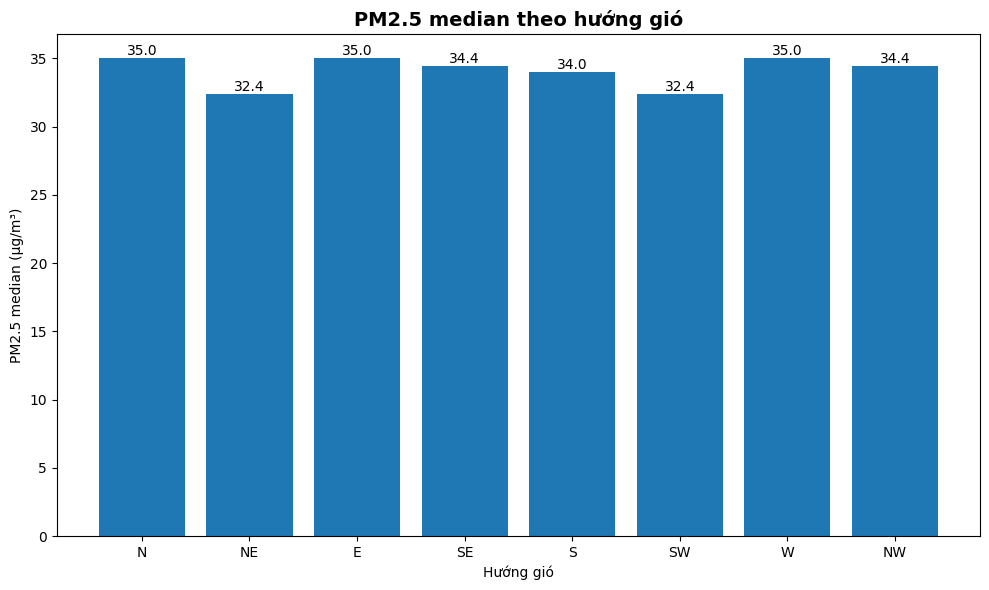

In [36]:
plt.figure(figsize=(10, 6))
bars = plt.bar(
    wind_sector_summary.index,
    wind_sector_summary['PM25_median']
)

plt.title('PM2.5 median theo hướng gió',
          fontsize=14, fontweight='bold')
plt.xlabel('Hướng gió')
plt.ylabel('PM2.5 median (µg/m³)')

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:.1f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()


**Nhận xét.** Xét cả năm, hướng gió gần như không tạo khác biệt:
ba hướng Bắc, Đông và Tây cùng có median 35.0, thấp nhất là Đông Bắc và Tây Nam (32.4), chênh chỉ 2.6 µg/m³.
Nếu xét theo mean thì gió Bắc cao nhất (47.7), nhưng mean bị các đỉnh kéo lên nên không đáng tin bằng median.

Chênh lệch nhỏ như vậy chưa đủ để nói hướng nào ô nhiễm hơn hay nguồn thải nằm ở đâu.
Phần 10.7 tách thêm theo tốc độ gió để xem yếu tố nào thực sự chi phối.

## 10.7 Hướng gió × tốc độ gió

Speed_group,Gió yếu,Gió vừa,Gió mạnh
Wind_sector,,,
N,44.000,34.000,26.000
NE,40.600,32.400,25.800
E,37.400,33.400,34.000
SE,36.400,34.400,32.400
S,37.000,33.000,33.000
SW,37.200,31.100,25.800
W,38.400,35.000,25.800
NW,41.000,35.400,28.000


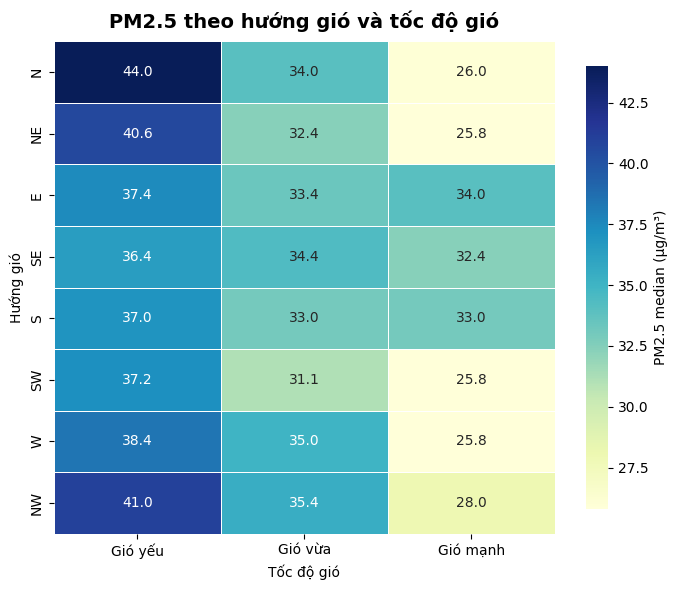

In [37]:
wind_data['Speed_group'] = pd.qcut(wind_data['Wind Speed'], q=3,
                                         labels=['Gió yếu', 'Gió vừa', 'Gió mạnh'], duplicates='drop')

wind_interaction = wind_data.pivot_table(index='Wind_sector', columns='Speed_group',
                                         values='PM25', aggfunc='median', observed=False).reindex(wind_order)

display(wind_interaction)

plt.figure(figsize=(7, 6))
ax = sns.heatmap(wind_interaction, annot=True, fmt='.1f', cmap='YlGnBu', linewidths=0.6,
                 cbar_kws={'label': 'PM2.5 median (µg/m³)', 'shrink': 0.9})

ax.set_title('PM2.5 theo hướng gió và tốc độ gió', fontsize=14, fontweight='bold', pad=10)
ax.set_xlabel('Tốc độ gió')
ax.set_ylabel('Hướng gió')

plt.tight_layout()
plt.show()


**Nhận xét.** Khi tách theo tốc độ gió, bức tranh rõ hơn nhiều.

Hướng Bắc với gió yếu có PM2.5 trung vị 44.0 nhưng với gió mạnh chỉ còn 26.0.
Cả 8 hướng đều giảm khi gió mạnh, nghĩa là **tốc độ gió chi phối mạnh hơn hướng gió**.

Vì vậy mô hình nên có biến "lặng gió" riêng chứ không chỉ dùng giá trị tốc độ gió liên tục.
Nếu vẫn dùng hướng gió thì phải ở dạng tuần hoàn (sin/cos) thay vì số độ thô,
nhưng nên kỳ vọng đóng góp của nó nhỏ.

# XI. Các đợt PM2.5 cao có đặc điểm gì?

## 11.1 Kiểm tra các peak cao nhất có phải spike đơn lẻ không

In [ ]:
peak_check = ts[['PM25', 'PM10', 'NO2', 'O3', 'CO', 'SO2']].copy()

peak_check['PM25_prev1h'] = peak_check['PM25'].shift(1)
peak_check['PM25_next1h'] = peak_check['PM25'].shift(-1)

peak_check['Neighbor_median'] = peak_check[['PM25_prev1h', 'PM25_next1h']].median(axis=1)

peak_check['Peak_to_neighbor'] = (peak_check['PM25'] / peak_check['Neighbor_median'])

top_peaks = (peak_check .sort_values('PM25', ascending=False) .head(20))

display(top_peaks)

**Nhận xét.** Các mốc PM2.5 cao nhất phần lớn không phải nhiễu đơn lẻ.
Ở phần lớn trường hợp, giờ trước và giờ sau cũng tăng cao tương ứng, và PM10 đi cùng chiều.

Ngoại lệ đáng chú ý là mốc 400 µg/m³ ngày 07/02/2024: đó là một giờ duy nhất, cách xa mức xung quanh,
và PM2.5 bằng đúng PM10 (xem mục 4.2). Những điểm như vậy nhiều khả năng là lỗi dữ liệu hoặc bị chặn trần,
nên cần xem xét riêng thay vì để lẫn vào tập huấn luyện.

## 11.2 Xác định episode PM2.5 cao

In [39]:
# P90 chỉ dùng làm ngưỡng exploratory
high_threshold = ts['PM25'].quantile(0.90)

episode_data = ts[['PM25']].copy()
episode_data['High'] = episode_data['PM25'] > high_threshold

episode_data['Group'] = (episode_data['High'] != episode_data['High'].shift(1)).cumsum()

episodes = []

for _, part in episode_data[episode_data['High']].groupby('Group'):
    episodes.append({
        'Start': part.index.min(),
        'End': part.index.max(),
        'Duration_h': len(part),
        'Mean_PM25': part['PM25'].mean(),
        'Peak_PM25': part['PM25'].max(),
        'Peak_time': part['PM25'].idxmax()
    })

episodes = pd.DataFrame(episodes)

print('Ngưỡng P90:', round(high_threshold, 2))
print('Số episode:', len(episodes))

if len(episodes) > 0:
    print('Median thời lượng:', episodes['Duration_h'].median(), 'giờ')
    print('Episode dài nhất:', episodes['Duration_h'].max(), 'giờ')
    print('Peak lớn nhất:', round(episodes['Peak_PM25'].max(), 2))
    display(episodes .sort_values('Peak_PM25', ascending=False) .head(10))

Ngưỡng P90: 83.8
Số episode: 913
Median thời lượng: 2.0 giờ
Episode dài nhất: 41 giờ
Peak lớn nhất: 400.0


,Start,End,Duration_h,Mean_PM25,Peak_PM25,Peak_time
344,2024-02-07 19:00:00,2024-02-07 19:00:00,1,400.000,400.000,2024-02-07 19:00:00
655,2025-03-20 20:00:00,2025-03-21 21:00:00,26,144.712,390.900,2025-03-20 23:00:00
275,2023-12-14 03:00:00,2023-12-14 07:00:00,5,162.400,355.500,2023-12-14 03:00:00
34,2022-04-07 17:00:00,2022-04-08 09:00:00,17,245.994,349.600,2022-04-08 04:00:00
588,2025-01-02 17:00:00,2025-01-03 14:00:00,22,195.105,331.800,2025-01-02 23:00:00
774,2025-12-12 00:00:00,2025-12-13 10:00:00,35,170.583,290.200,2025-12-13 06:00:00
342,2024-01-31 21:00:00,2024-02-02 03:00:00,31,167.216,286.200,2024-02-01 23:00:00
228,2023-11-19 18:00:00,2023-11-20 09:00:00,16,201.875,270.100,2023-11-19 20:00:00
251,2023-11-28 20:00:00,2023-11-29 18:00:00,23,159.370,264.100,2023-11-29 03:00:00
351,2024-03-04 20:00:00,2024-03-05 14:00:00,19,149.432,263.000,2024-03-04 22:00:00


**Nhận xét.** Với ngưỡng P90 khoảng 84 µg/m³, cả chuỗi có 913 đợt.
Thời lượng trung vị chỉ 2 giờ nhưng đợt dài nhất kéo tới 41 giờ.

Con số này nói lên hai điều. Phần lớn là đợt ngắn một đến hai giờ, tức là dự báo 3 đến 6 giờ là đủ hữu ích.
Nhưng vẫn có một nhóm đợt kéo dài hơn một ngày, và đây mới là nhóm gây rủi ro sức khỏe thực sự.
Đánh giá mô hình nên có chỉ số riêng cho việc bắt được đợt dài.

## 11.3 Episode theo mùa

,So_episode,Median_duration,Mean_duration,Max_duration,Median_peak
Season,,,,,
Xuân,223,1.000,3.740,26,103.000
Hạ,67,1.000,1.701,7,110.000
Thu,222,2.500,4.131,23,109.200
Đông,401,3.000,5.446,41,111.300


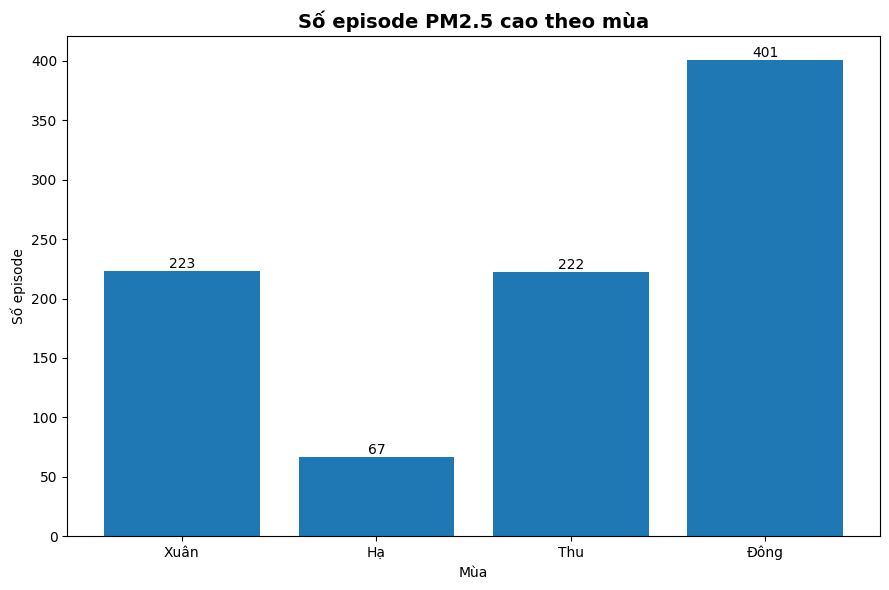

In [40]:
if len(episodes) > 0:
    episodes['Month'] = episodes['Start'].dt.month
    episodes['Season'] = episodes['Month'].apply(get_season)

    episode_season = episodes.groupby('Season').agg(
        So_episode=('Duration_h', 'size'),
        Median_duration=('Duration_h', 'median'),
        Mean_duration=('Duration_h', 'mean'),
        Max_duration=('Duration_h', 'max'),
        Median_peak=('Peak_PM25', 'median')
    ).reindex(['Xuân', 'Hạ', 'Thu', 'Đông'])

    display(episode_season)

    plt.figure(figsize=(9, 6))
    bars = plt.bar(episode_season.index, episode_season['So_episode'])

    plt.title('Số episode PM2.5 cao theo mùa', fontsize=14, fontweight='bold')
    plt.xlabel('Mùa')
    plt.ylabel('Số episode')

    for bar in bars:
        val = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, val, f'{int(val)}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

**Nhận xét.** Mùa đông vừa nhiều đợt nhất vừa kéo dài nhất: 401 đợt, trung vị 3 giờ, dài nhất 41 giờ.
Mùa hạ chỉ có 67 đợt và đợt dài nhất 7 giờ.

Nồng độ trung vị tại đỉnh các đợt khá giống nhau giữa các mùa (khoảng 103 đến 111 µg/m³),
nghĩa là độ cao đỉnh không phụ thuộc mùa, cái khác là tần suất và độ dài.
Vì vậy sai số mô hình nhiều khả năng tập trung ở mùa đông, và cần báo cáo riêng.

## 11.4 Profile PM2.5 quanh peak episode

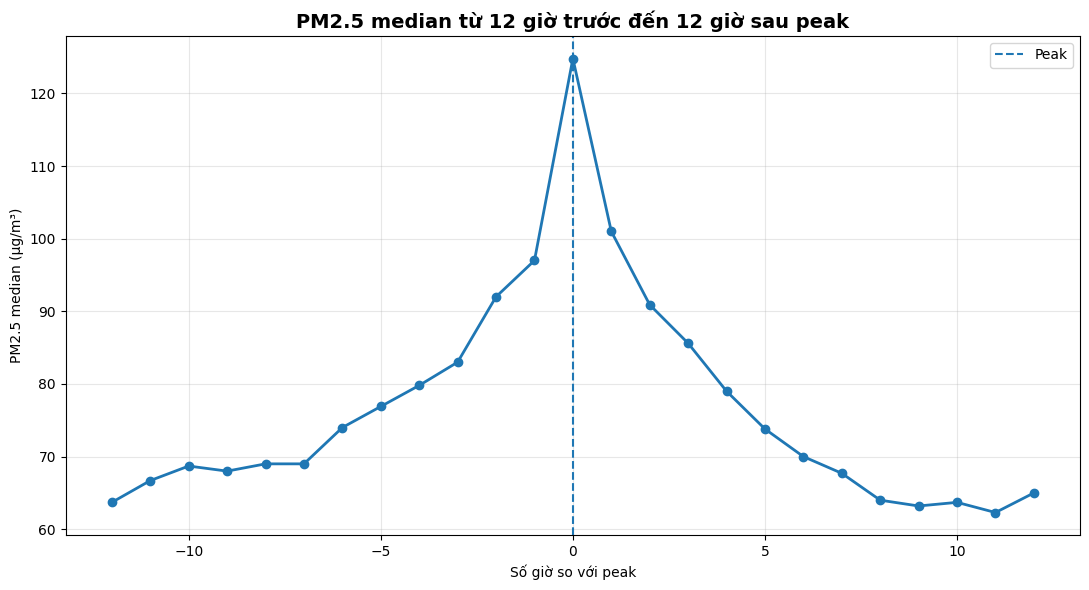

In [41]:
# Chỉ lấy các episode dài ít nhất 2 giờ để tránh quá nhiều spike một giờ
selected_peaks = []

if len(episodes) > 0:
    selected_peaks = (episodes.loc[episodes['Duration_h'] >= 2, 'Peak_time'] .dropna() .tolist())

profiles = []

for peak_time in selected_peaks:
    start = peak_time - pd.Timedelta(hours=12)
    end = peak_time + pd.Timedelta(hours=12)

    part = ts.loc[start:end, ['PM25']].copy()

    if len(part) == 25:
        part['Relative_hour'] = range(-12, 13)
        profiles.append(part[['Relative_hour', 'PM25']])

if len(profiles) > 0:
    profile_df = pd.concat(profiles)

    profile_summary = profile_df.groupby('Relative_hour')['PM25'].median()

    plt.figure(figsize=(11, 6))
    plt.plot(profile_summary.index, profile_summary.values, marker='o', linewidth=2)

    plt.axvline(0, linestyle='--', label='Peak')
    plt.title('PM2.5 median từ 12 giờ trước đến 12 giờ sau peak', fontsize=14, fontweight='bold')
    plt.xlabel('Số giờ so với peak')
    plt.ylabel('PM2.5 median (µg/m³)')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print('Không đủ episode để tạo profile.')

**Nhận xét.** Trước đỉnh, PM2.5 tăng dần trong khoảng 6 đến 8 giờ rồi đạt đỉnh, sau đó giảm nhanh hơn lúc tăng.
Dạng bất đối xứng này cho thấy đợt ô nhiễm thường được tích lũy dần (điều kiện khuếch tán kém kéo dài)
nhưng được giải tỏa nhanh khi thời tiết thay đổi (gió hoặc mưa đến).

Hàm ý cho mô hình: dự báo trước đỉnh là việc khó hơn dự báo sau đỉnh,
vì giai đoạn trước cần nhận ra tín hiệu tích lũy chứ không chỉ phản ứng với giá trị cao đã có.

# XII. Dữ liệu có distribution drift theo năm không?

In [42]:
year_stats = eda_time.groupby('Year')['PM25'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    q25=lambda x: x.quantile(0.25),
    q75=lambda x: x.quantile(0.75),
    p90=lambda x: x.quantile(0.90),
    p95=lambda x: x.quantile(0.95)
)

display(year_stats)


,count,mean,median,std,q25,q75,p90,p95
Year,,,,,,,,
2022,8472,40.099,31.300,31.023,21.200,48.500,75.800,101.000
2023,8760,43.703,34.400,33.755,22.600,52.600,81.600,118.200
2024,8784,45.400,36.400,35.683,21.200,55.600,92.000,123.400
2025,8760,45.909,36.000,33.817,25.000,57.000,90.000,114.000
2026,5832,40.497,35.000,24.863,25.000,47.050,71.000,91.360


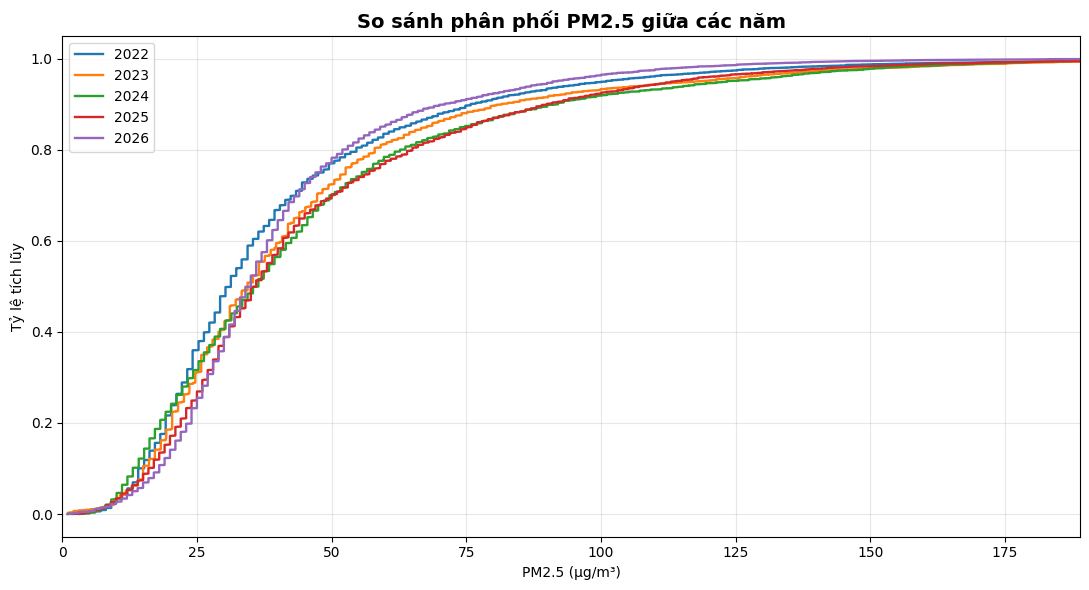

In [43]:
years = sorted(eda_time['Year'].dropna().unique())

plt.figure(figsize=(11, 6))

for year in years:
    part = eda_time.loc[
        eda_time['Year'] == year,
        'PM25'
    ].dropna()

    # ECDF theo năm
    x = np.sort(part.values)
    y = np.arange(1, len(x) + 1) / len(x)

    plt.plot(x, y, label=str(year), linewidth=1.7)

plt.title('So sánh phân phối PM2.5 giữa các năm',
          fontsize=14, fontweight='bold')
plt.xlabel('PM2.5 (µg/m³)')
plt.ylabel('Tỷ lệ tích lũy')
plt.legend()
plt.grid(alpha=0.3)
plt.xlim(0, pm25.quantile(0.995))
plt.tight_layout()
plt.show()


2026 chưa đủ 12 tháng nên không nên chỉ so mean cả năm 2026 với các năm đầy đủ. Khi cần kiểm định drift, nên so cùng một khoảng tháng.


In [44]:
from scipy.stats import mannwhitneyu

jan_aug = eda_time[eda_time['Month'].between(1, 8)].copy()

pm25_2026 = jan_aug.loc[jan_aug['Year'] == 2026, 'PM25'].dropna()

pm25_old = jan_aug.loc[jan_aug['Year'].between(2022, 2025), 'PM25'].dropna()

stat, p_value = mannwhitneyu(pm25_2026, pm25_old, alternative='two-sided')

print('So sánh Jan-Aug 2026 với Jan-Aug 2022-2025')
print('Median 2026:', round(pm25_2026.median(), 2))
print('Median 2022-2025:', round(pm25_old.median(), 2))
print('Chênh median:', round(pm25_2026.median() - pm25_old.median(), 2))
print('p-value:', p_value)

So sánh Jan-Aug 2026 với Jan-Aug 2022-2025
Median 2026: 35.0
Median 2022-2025: 32.2
Chênh median: 2.8
p-value: 1.0827342484882169e-15


In [45]:
from scipy.stats import kruskal

year_groups = [eda_time.loc[eda_time['Year'] == y, 'PM25'].dropna().values
               for y in sorted(eda_time['Year'].dropna().unique())]

stat, p_kw = kruskal(*year_groups)

print('Kruskal-Wallis toàn bộ các năm')
print('H =', round(stat, 2), '| p =', p_kw)

Kruskal-Wallis toàn bộ các năm
H = 212.37 | p = 8.205447649567832e-45


**Nhận xét.** Phân phối PM2.5 thay đổi giữa các năm và xu hướng tăng khá rõ:
trung bình 40.1 (2022) lên 45.9 (2025). So sánh công bằng cùng khoảng tháng 1 đến 8,
năm 2026 vẫn cao hơn giai đoạn 2022-2025 với p rất nhỏ.

Đây là distribution drift, và nó có hệ quả trực tiếp tới cách chia dữ liệu.
Nếu chia ngẫu nhiên, mô hình sẽ học được đặc điểm của năm tương lai rồi được đánh giá trên chính năm đó,
kết quả sẽ lạc quan hơn thực tế. Vì vậy phải dùng walk-forward: train trên quá khứ, test trên tương lai.

Ngoài ra cũng nên xem lại các kết luận về xu hướng dài hạn, vì dữ liệu chỉ có hơn 4 năm.

# XIII. Yếu tố ngoài khí tượng

Phần trên chỉ dùng dữ liệu khí tượng và chất ô nhiễm của nguồn dữ liệu gốc.
Ngoài ra còn mấy nguồn có thể ảnh hưởng tới PM2.5 mà dữ liệu gốc không có:
độ ẩm đất (bụi đất bay lên), chiều cao lớp biên khí quyển (khả năng pha loãng theo chiều đứng),
và cháy rơm rạ ngoại thành (nguồn thải theo mùa).

Các cột này đã được ghép vào `cleaned_data_v2.csv`, xem `notebooks/01B_merge_external_data.ipynb`.
Phần này kiểm tra xem chúng có thực sự mang thông tin mới không.

In [ ]:
v2 = pd.read_csv('../data/processed/cleaned_data_v2.csv')
v2['Local Time'] = pd.to_datetime(v2['Local Time'])
v2 = v2.set_index('Local Time').sort_index()

# Bỏ AQI như ở bản gốc, nếu không AQI sẽ bị tính nhầm là cột mới
v2 = v2.drop(columns=[c for c in ['AQI'] if c in v2.columns])

new_cols = [c for c in v2.columns if c not in ts.columns]

print('Số cột trong bản gốc:', ts.shape[1])
print('Số cột trong bản ghép thêm:', v2.shape[1])
print('Các cột mới:')
print(new_cols)

## 13.1 Tương quan có còn giữ sau khi loại mùa vụ không

Giống cách làm ở mục 10.4: tính tương quan gốc, rồi tính lại sau khi trừ median từng tháng.
Biến nào mất tương quan ở cột thứ hai thì chỉ là biến mùa, không phải cơ chế.

Bảng có cả Pearson (r) và Spearman (rho). Phần nhận xét dùng Pearson như bản trước;
cột Spearman dùng để so trực tiếp với mục 10 (vốn dùng Spearman vì PM2.5 lệch phải).

In [ ]:
from scipy.stats import pearsonr, spearmanr

new_rows = []

for col in new_cols:
    pair = v2[['PM25', col]].dropna()

    if len(pair) < 1000:
        continue

    r_all, _ = pearsonr(pair['PM25'], pair[col])
    rho_all, _ = spearmanr(pair['PM25'], pair[col])

    month = pair.index.month
    anom = pair - pair.groupby(month).transform('median')
    r_anom, p_anom = pearsonr(anom['PM25'], anom[col])
    rho_anom, _ = spearmanr(anom['PM25'], anom[col])

    new_rows.append({
        'Biến': col,
        'r gốc': r_all,
        'r sau trừ mùa': r_anom,
        'p sau trừ mùa': p_anom,
        'rho gốc': rho_all,
        'rho sau trừ mùa': rho_anom,
        'Số giờ': len(pair),
        'Thiếu (%)': v2[col].isna().mean() * 100
    })

new_corr = pd.DataFrame(new_rows).sort_values('r gốc', key=abs, ascending=False)
display(new_corr.round(3).reset_index(drop=True))

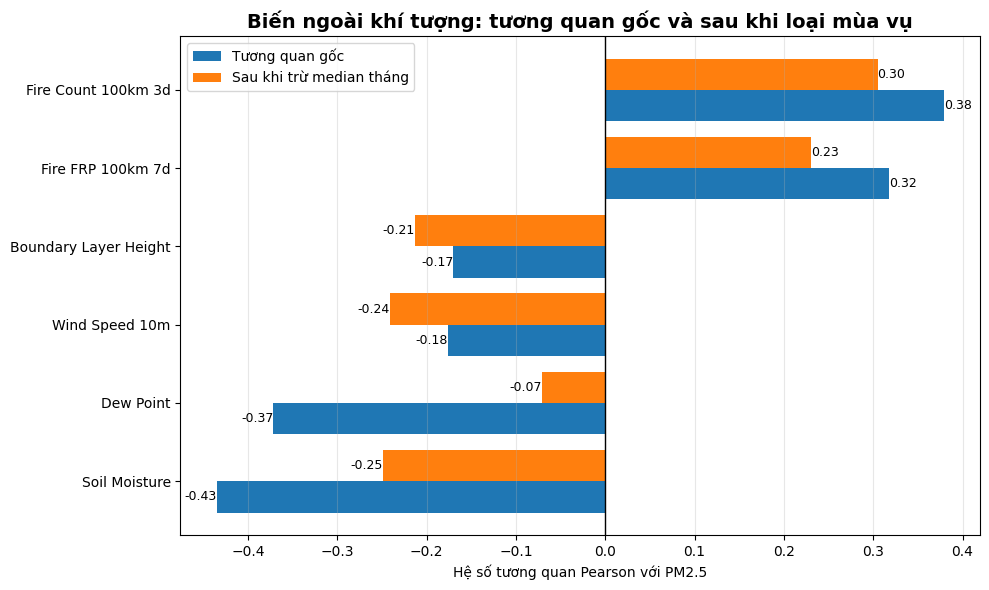

In [48]:
plot_cols = [c for c in ['Soil Moisture', 'Boundary Layer Height', 'Wind Speed 10m',
                       'Fire Count 100km 3d', 'Fire FRP 100km 7d', 'Dew Point']
             if c in new_corr['Biến'].values]

plot_df = new_corr.set_index('Biến').loc[plot_cols].sort_values('r gốc')

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(y - 0.2, plot_df['r gốc'], height=0.4, label='Tương quan gốc')
ax.barh(y + 0.2, plot_df['r sau trừ mùa'], height=0.4, label='Sau khi trừ median tháng')

for k, (val_goc, val_sau) in enumerate(zip(plot_df['r gốc'], plot_df['r sau trừ mùa'])):
    ax.text(val_goc, k - 0.2, f'{val_goc:.2f}', va='center',
            ha='left' if val_goc >= 0 else 'right', fontsize=9)
    ax.text(val_sau, k + 0.2, f'{val_sau:.2f}', va='center',
            ha='left' if val_sau >= 0 else 'right', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(plot_df.index)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Hệ số tương quan Pearson với PM2.5')
ax.set_title('Biến ngoài khí tượng: tương quan gốc và sau khi loại mùa vụ',
             fontsize=14, fontweight='bold')
ax.legend()
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

,Soil_median,PM25_median,N
Group,,,
"(0.055, 0.24]",0.193,54.000,8135
"(0.24, 0.304]",0.277,39.400,8151
"(0.304, 0.352]",0.329,34.000,8238
"(0.352, 0.395]",0.374,30.000,8046
"(0.395, 0.442]",0.417,22.300,8038


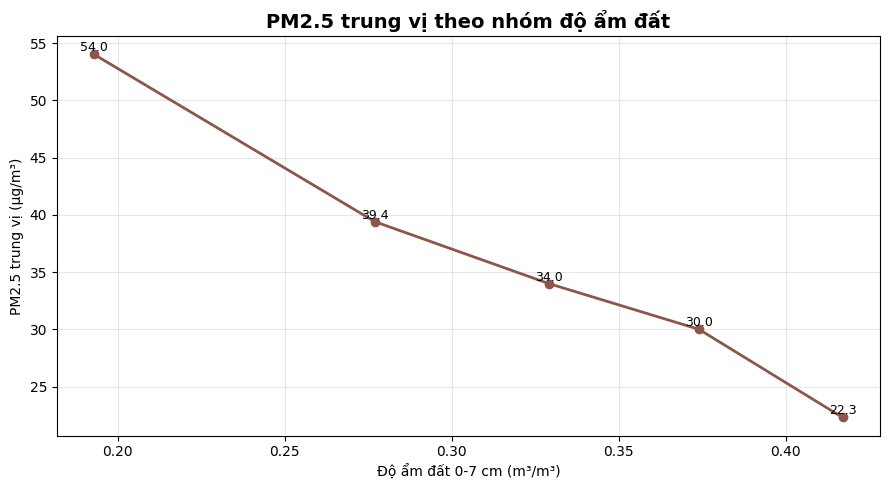

In [49]:
soil = v2[['Soil Moisture', 'PM25']].dropna().copy()
soil['Group'] = pd.qcut(soil['Soil Moisture'], q=5, duplicates='drop')

soil_summary = soil.groupby('Group', observed=False).agg(
    Soil_median=('Soil Moisture', 'median'),
    PM25_median=('PM25', 'median'),
    N=('PM25', 'size')
)
display(soil_summary)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(soil_summary['Soil_median'], soil_summary['PM25_median'],
        marker='o', linewidth=2, color='tab:brown')

for x, val in zip(soil_summary['Soil_median'], soil_summary['PM25_median']):
    ax.text(x, val, f'{val:.1f}', ha='center', va='bottom', fontsize=9)

ax.set_title('PM2.5 trung vị theo nhóm độ ẩm đất', fontsize=14, fontweight='bold')
ax.set_xlabel('Độ ẩm đất 0-7 cm (m³/m³)')
ax.set_ylabel('PM2.5 trung vị (µg/m³)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Hình trên cho thấy đất càng ẩm thì PM2.5 càng thấp, và mức giảm khá đều chứ không bão hòa ngay.
Đây là quan hệ mà dữ liệu khí tượng của trạm không nắm được: trời khô hanh và đất khô là hai chuyện khác nhau,
nhưng cùng đẩy bụi đất lên không khí.

**Nhận xét.** Độ ẩm đất và số điểm cháy là hai biến giữ được tương quan sau khi loại mùa vụ.

Độ ẩm đất giảm từ -0.44 xuống -0.25 nhưng vẫn còn rõ: đất và không khí khô làm bụi dễ bay lên.
Số điểm cháy trong bán kính 100 km gần như không mất tín hiệu (0.38 xuống 0.31), nghĩa là khói vận chuyển
từ ngoại thành có ảnh hưởng thật chứ không chỉ trùng với mùa khô.

Ngược lại điểm sương giảm mạnh từ -0.37 xuống -0.07. Phần lớn tác dụng trước đó chỉ là trùng mùa.

## 13.2 Kiểm tra đa cộng tuyến với biến đã có

Trước khi thêm biến mới cần chắc nó không trùng thông tin với biến cũ.

In [50]:
pairs = [
    ('Wind Speed', 'Wind Speed 10m'),
    ('Temperature', 'Dew Point'),
    ('Pressure', 'Dew Point'),
    ('Temperature', 'Soil Moisture'),
]

rows = []

for a, b in pairs:
    pair = v2[[a, b]].dropna()
    r = pair[a].corr(pair[b])
    rows.append({
        'Cặp biến': f'{a} ~ {b}',
        'r': r,
        'Kết luận': 'trùng lặp cao, cân nhắc bỏ' if abs(r) > 0.85 else 'giữ được'
    })

trung_lap = pd.DataFrame(rows)
display(trung_lap.round(3))

cao = trung_lap[trung_lap['r'].abs() > 0.85]

if len(cao) > 0:
    print('Các cặp trùng lặp cần xem lại:')
    print(cao['Cặp biến'].tolist())
else:
    print('Không có cặp nào trùng lặp nghiêm trọng')

,Cặp biến,r,Kết luận
0,Wind Speed ~ Wind Speed 10m,0.468,giữ được
1,Temperature ~ Dew Point,0.859,"trùng lặp cao, cân nhắc bỏ"
2,Pressure ~ Dew Point,-0.873,"trùng lặp cao, cân nhắc bỏ"
3,Temperature ~ Soil Moisture,0.234,giữ được


Các cặp trùng lặp cần xem lại:
['Temperature ~ Dew Point', 'Pressure ~ Dew Point']


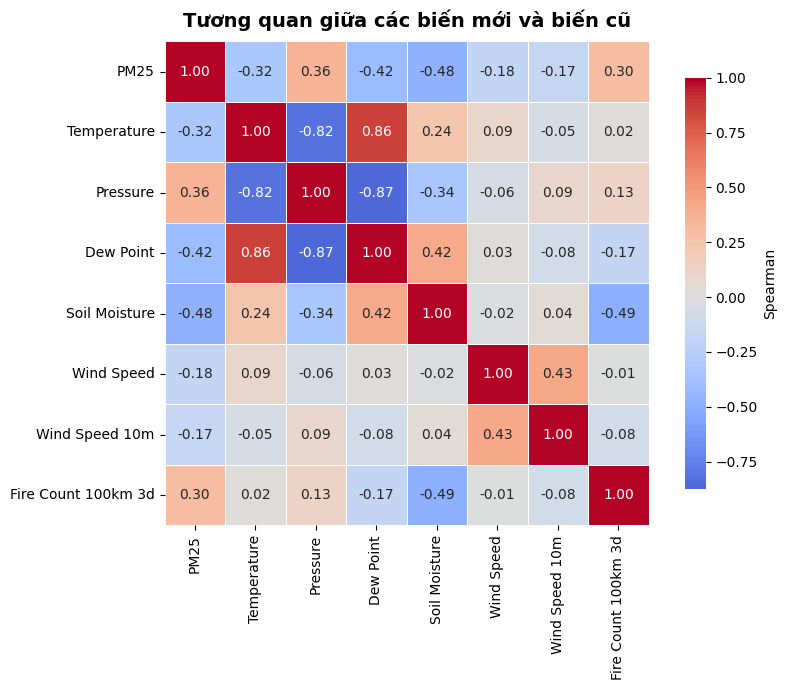

In [51]:
check_matrix = v2[['PM25', 'Temperature', 'Pressure', 'Dew Point',
                     'Soil Moisture', 'Wind Speed', 'Wind Speed 10m',
                     'Fire Count 100km 3d']].dropna()

plt.figure(figsize=(9, 7))

sns.heatmap(check_matrix.corr(method='spearman'),
            annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.6,
            cbar_kws={'label': 'Spearman', 'shrink': 0.85})

plt.title('Tương quan giữa các biến mới và biến cũ', fontsize=14, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()

**Nhận xét.** Điểm sương trùng với cả nhiệt độ (r = 0.86) và áp suất (r = -0.87),
lại vừa mất tương quan sau khi loại mùa vụ. Biến này không nên dùng.

Các cặp còn lại đều dưới ngưỡng 0.85 nên có thể giữ cùng nhau.

## 13.3 Cột cháy có độ phân giải thời gian thấp

Dữ liệu vệ tinh cháy chỉ cho biết tổng số điểm cháy trong ngày, nên khi ghép vào chuỗi giờ
thì cả 24 giờ trong ngày nhận cùng một giá trị. Điều này có nghĩa là feature cháy không thể
tách biệt được thay đổi trong ngày, dù tương quan ở mức ngày là tốt.

Vì vậy tuy tương quan đẹp, vẫn phải kiểm tra bằng ablation xem có giảm được MAE ở horizon ngắn không.
Kết quả kiểm tra trước đó cho thấy gần như không giảm, vì PM10 đã bao trùm phần lớn tín hiệu bụi.
Vai trò phù hợp hơn của dữ liệu cháy là giải thích nguồn ô nhiễm trong báo cáo, không phải đưa vào mô hình dự báo 3 giờ.

Hình dưới cho thấy vấn đề độ phân giải: đường cháy chỉ đổi giá trị theo ngày,
do đó khi ghép vào chuỗi giờ nó tạo thành các bậc thang.

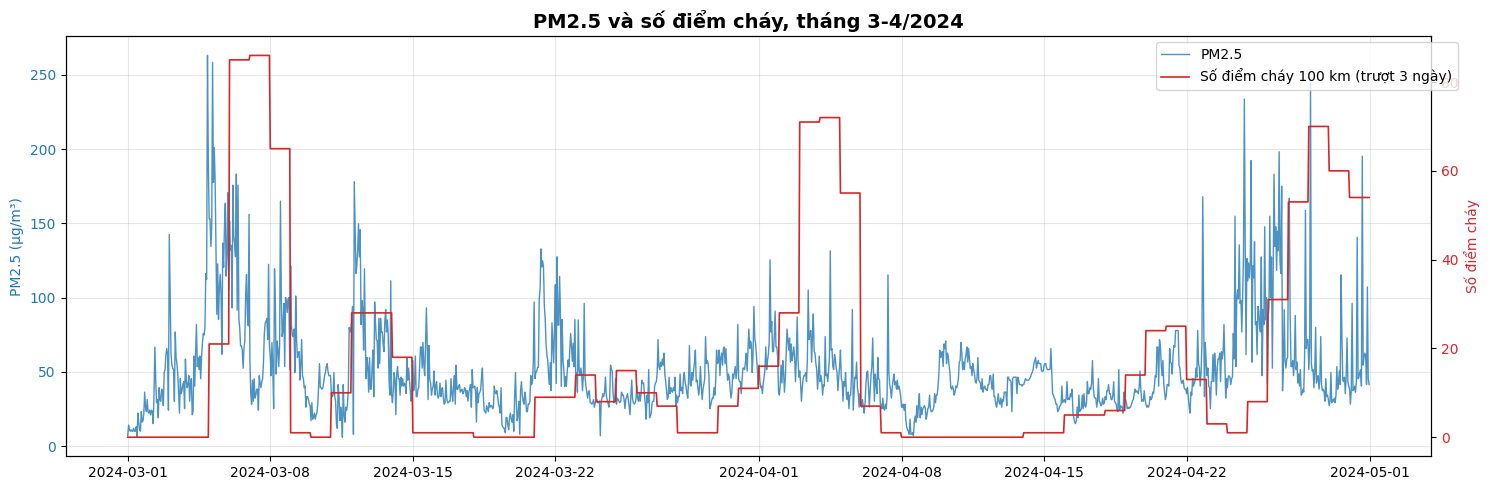

In [52]:
fire_view = v2.loc['2024-03-01':'2024-04-30', ['Fire Count 100km 3d', 'PM25']].copy()

fig, ax1 = plt.subplots(figsize=(15, 5))

ax1.plot(fire_view['PM25'], color='tab:blue', alpha=0.8, linewidth=1, label='PM2.5')
ax1.set_ylabel('PM2.5 (µg/m³)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.plot(fire_view['Fire Count 100km 3d'], color='tab:red', linewidth=1.2, label='Số điểm cháy 100 km (trượt 3 ngày)')
ax2.set_ylabel('Số điểm cháy', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('PM2.5 và số điểm cháy, tháng 3-4/2024', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3)
fig.legend(loc='upper right', bbox_to_anchor=(0.98, 0.92))
plt.tight_layout()
plt.show()

# XIV. Tổng hợp

Bảng dưới gom lại những gì tìm được và việc cần làm tương ứng ở bước sau.

In [ ]:
n_episode = len(episodes)
n_episode_winter = int((episodes['Season'] == 'Đông').sum())

tong_hop = pd.DataFrame([
    ('Dữ liệu liên tục', f'{len(ts):,} giờ, không thiếu giờ nào', 'Không cần nội suy thời gian'),
    ('Có dấu hiệu chặn trần / lỗi ở đỉnh', 'PM2.5 = PM10 = 400 ngày 07/02/2024', 'Xem mục 4.2, xử lý các giờ PM2.5 >= PM10 ở bước làm sạch'),
    ('Đuôi phải dài', f'median {pm25.median():.1f}, max {pm25.max():.0f}', 'Biến đổi log cho target, báo cáo sai số riêng cho đỉnh'),
    ('Mùa rõ', 'Đông 49.0 so với Hạ 24.2', 'Cần biến tháng dạng tuần hoàn'),
    ('Chu kỳ ngày', 'đỉnh giờ cao điểm sáng và tối', 'Cần biến giờ dạng tuần hoàn'),
    ('ACF chuỗi gốc bị mùa vụ thổi phồng', '0.26 ở lag 168 giờ, giảm mạnh sau khi loại mùa (7.1)', 'Chọn window bằng thử nghiệm, đưa mùa vào bằng biến lịch'),
    ('Sai số tăng nhanh ở 3 giờ', '8.2 sang 13.1 µg/m³', 'Đánh giá riêng từng horizon'),
    ('24 giờ dễ hơn 12 giờ', '18.9 so với 20.1 µg/m³', 'Không coi MAE 24h < 12h là lỗi'),
    ('PM10 chi phối', 'Spearman 0.953', 'PM10 là đầu vào chính, đồng thời là rủi ro khi dữ liệu PM10 lỗi'),
    ('Quan hệ phi tuyến', 'gió 0.8 sang 3.0 m/s làm PM25 39 xuống 30', 'Dùng mô hình phi tuyến'),
    ('Áp suất và nhiệt độ chủ yếu là biến mùa', '0.362 xuống 0.013 sau khi loại mùa', 'Không diễn giải là nguyên nhân trực tiếp'),
    ('Tốc độ gió có tác dụng độc lập', '-0.182 thành -0.234', 'Giữ Wind Speed và thêm cờ lặng gió'),
    ('Mưa lớn mới rửa được bụi', '36.4 xuống 22.3 µg/m³', 'Dùng cường độ mưa và số giờ từ trận mưa cuối'),
    ('Hướng gió gần như không khác biệt', 'median 32.4 đến 35.0 giữa 8 hướng', 'Nếu dùng thì ở dạng sin/cos, kỳ vọng đóng góp nhỏ'),
    ('Đợt ô nhiễm ngắn, mùa đông nhiều', f'{n_episode} đợt, Đông {n_episode_winter}', 'Đánh giá riêng khả năng bắt đỉnh'),
    ('Phân phối lệch giữa các năm', '40.1 lên 45.9, p rất nhỏ', 'Bắt buộc dùng walk-forward'),
    ('Độ ẩm đất có tín hiệu thật', '-0.44 xuống -0.25 sau khi loại mùa', 'Đưa vào feature engineering'),
    ('Điểm sương trùng nhiệt độ', 'r = 0.86 với Temperature', 'Bỏ biến này'),
    ('Cháy chỉ có độ phân giải ngày', 'cả 24 giờ cùng một giá trị', 'Dùng để giải thích nguồn, không ưu tiên cho dự báo 3 giờ'),
], columns=['Phát hiện', 'Số liệu', 'Việc cần làm'])

display(tong_hop)

**Nhận xét.** Ba điểm quan trọng nhất:

Một là phần lớn tác dụng của áp suất và nhiệt độ thực chất là do chúng cùng thay đổi theo mùa với PM2.5.
Sau khi loại mùa vụ, hai biến này gần như mất tương quan, chỉ còn tốc độ gió là giữ được.

Hai là PM10 gần như đồng nghĩa với PM2.5 ở tầm ngắn hạn. Đây là điểm mạnh cho dự báo 3 giờ
nhưng cũng là điểm yếu: nếu dữ liệu PM10 lỗi thì mô hình mất phần lớn năng lực.

Ba là phân phối dữ liệu thay đổi khá rõ giữa các năm, nên chia dữ liệu ngẫu nhiên sẽ cho kết quả lạc quan hơn thực tế.
Đây là lý do chọn walk-forward.

# XV. Những gì chưa trả lời được

Ghi ra để không phải né khi bị hỏi.

**Dữ liệu có đại diện cho cả quận không.** Không. Cả quận nằm trong một ô lưới khoảng 10 km của nguồn dữ liệu,
nên các toạ độ khác nhau trong quận cho cùng một chuỗi. Muốn đại diện từng phường phải có nhiều trạm quan trắc mặt đất.

**Nguồn dữ liệu là lưới mô hình hay trạm đo.** Vì cả quận cho cùng một chuỗi, dữ liệu nhiều khả năng là
sản phẩm mô hình hoặc nội suy theo lưới, không phải một trạm quan trắc. Cần ghi rõ tên nguồn trong báo cáo.
Điều này cũng ảnh hưởng tới cách hiểu tương quan PM10–PM2.5 (mục IX) và các giá trị bằng nhau ở mục 4.2.

**EDA có nhìn thấy giai đoạn Test.** Các phân tích ở đây chạy trên toàn chuỗi. Mục 10.4b đã kiểm tra lại
kết luận chính trên 70% đầu chuỗi, nhưng các quyết định chọn biến khác vẫn nên được coi là có rủi ro rò rỉ nhẹ.

**Biến đổi khí hậu.** Chưa kết luận được từ dữ liệu này. Có hơn 4 năm, trong khi cần 30 năm cho chuẩn khí hậu.
Phần riêng đã lấy dữ liệu ERA5 từ 1991 để có bối cảnh nhiệt độ, xem `results/climate_review/`.

**El Nino.** Đã kiểm tra với chỉ số ONI của NOAA, không có tương quan với PM2.5 (r = -0.09, p = 0.50).

**Giao thông.** Không có nguồn dữ liệu lưu lượng miễn phí cho Hà Nội. Chỉ dùng được biến giờ, ngày và ngày lễ làm đại diện.

**Bụi công trường.** Không có danh sách công trình theo thời gian. Có thể ước lượng bằng ảnh vệ tinh nhưng chưa làm.